In [1]:
# Đầu tiên chúng ta sẽ kiểm tra notebook
import sys
from pathlib import Path

# Notebook có thể chạy từ thư mục project hoặc thư mục notebooks.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Cho phép import các file Python trong project.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Python đang dùng:", sys.executable)
print("Thư mục project:", ROOT)

# Dừng sớm nếu chọn nhầm thư mục hoặc môi trường.
assert (ROOT / "config.py").is_file(), "Chưa chạy trong đúng project."
assert Path(sys.prefix).resolve() == (ROOT / ".venv").resolve(), (
    "Bạn cần chọn kernel .venv của project."
)

print("\nOK: notebook đang dùng đúng project và môi trường.")

Python đang dùng: d:\AI_Bussiness_Huflit\Đồ án\Industry_4_AI\.venv\Scripts\python.exe
Thư mục project: d:\AI_Bussiness_Huflit\Đồ án\Industry_4_AI

OK: notebook đang dùng đúng project và môi trường.


## 1. Đọc dữ liệu và chia tập train/test

Sử dụng các hàm của người 1 để đọc dữ liệu SECOM và chia
80/20 theo thời gian.

- X: các đặc trưng cảm biến/quy trình.
- y: nhãn, với 0 = Pass và 1 = Fail.
- timestamps: thời gian của từng mẫu.
- Train dùng để học, tuning và chọn ngưỡng.
- Test được giữ riêng để đánh giá cuối.

In [2]:
import pandas as pd
from IPython.display import display

from src.data_loader import load_data
from src.split import time_split

# Đọc dữ liệu bằng hàm đã có của người 1.
X, y, timestamps = load_data()

# Chia theo thời gian: mẫu cũ vào train, mẫu mới vào test.
X_train, X_test, y_train, y_test = time_split(
    X, y, timestamps
)

print("Kích thước toàn bộ:", X.shape)
print("Kích thước train:", X_train.shape)
print("Kích thước test:", X_test.shape)

# Tạo bảng thống kê để quan sát trong notebook.
split_summary = pd.DataFrame(
    {
        "Số mẫu": [len(y_train), len(y_test)],
        "Số Pass": [
            int((y_train == 0).sum()),
            int((y_test == 0).sum()),
        ],
        "Số Fail": [
            int((y_train == 1).sum()),
            int((y_test == 1).sum()),
        ],
        "Tỷ lệ Fail (%)": [
            round(y_train.mean() * 100, 2),
            round(y_test.mean() * 100, 2),
        ],
    },
    index=["Train", "Test"],
)

display(split_summary)

# Kiểm tra đặc trưng và nhãn vẫn khớp nhau sau khi chia.
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("OK: đặc trưng và nhãn khớp nhau.")

Kích thước toàn bộ: (1567, 590)
Kích thước train: (1253, 590)
Kích thước test: (314, 590)


,Số mẫu,Số Pass,Số Fail,Tỷ lệ Fail (%)
Train,1253,1166,87,6.94
Test,314,297,17,5.41


OK: đặc trưng và nhãn khớp nhau.


In [3]:
# Xem 5 mẫu đầu và 8 đặc trưng đầu của train.
display(X_train.iloc[:5, :8])

# Xem nhãn tương ứng với đúng 5 mẫu đó.
display(y_train.iloc[:5].rename("Nhãn: 0=Pass, 1=Fail"))

,0,1,2,3,4,5,6,7
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235


0    0
1    0
2    1
3    0
4    0
Name: Nhãn: 0=Pass, 1=Fail, dtype: int64

## 2. Phân bố lớp trong tập train

Kiểm tra số mẫu Pass và Fail để hiểu mức độ mất cân bằng.
Mô hình cần phát hiện lớp Fail dù lớp này có ít mẫu hơn nhiều.

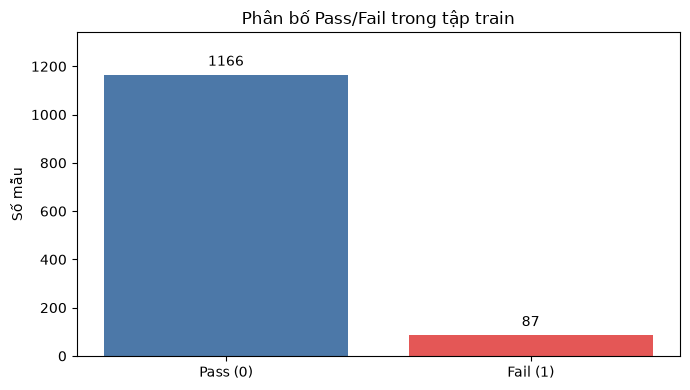

Tỷ lệ Fail trong train: 6.94%
Nếu luôn đoán Pass, accuracy vẫn đạt: 93.06%


In [4]:
import matplotlib.pyplot as plt

# Đếm nhãn trên TRAIN.
# reindex bảo đảm thứ tự luôn là 0=Pass, 1=Fail.
class_counts = y_train.value_counts().reindex([0, 1], fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Pass (0)", "Fail (1)"],
    class_counts.to_numpy(),
    color=["#4C78A8", "#E45756"],
)

ax.bar_label(bars, padding=4)
ax.set_title("Phân bố Pass/Fail trong tập train")
ax.set_ylabel("Số mẫu")
ax.set_ylim(0, class_counts.max() * 1.15)

plt.tight_layout()
plt.show()

fail_rate = (y_train == 1).mean()
always_pass_accuracy = (y_train == 0).mean()

print(f"Tỷ lệ Fail trong train: {fail_rate:.2%}")
print(f"Nếu luôn đoán Pass, accuracy vẫn đạt: {always_pass_accuracy:.2%}")

## 3. Kiểm tra pipeline tiền xử lý của người 1

Pipeline thực hiện:
- Bỏ cột thiếu quá nhiều.
- Điền giá trị thiếu bằng median và thêm cột đánh dấu thiếu.
- Bỏ cột hằng.
- Chuẩn hóa.
- Chọn 40 đặc trưng.

Chỉ fit trên train. Test sử dụng lại các bước đã học từ train.

In [5]:
import numpy as np
import config

from src.preprocess import build_preprocessor

# Pipeline này chỉ dùng để minh họa và kiểm tra.
demo_preprocessor = build_preprocessor(
    k_features=config.K_FEATURES
)

# Fit trên train, sau đó transform test.
X_train_demo = demo_preprocessor.fit_transform(
    X_train, y_train
)
X_test_demo = demo_preprocessor.transform(X_test)

preprocessing_summary = pd.DataFrame(
    {
        "Số mẫu": [len(X_train), len(X_test)],
        "Số cột trước xử lý": [
            X_train.shape[1],
            X_test.shape[1],
        ],
        "Số cột sau xử lý": [
            X_train_demo.shape[1],
            X_test_demo.shape[1],
        ],
        "Số ô NaN trước xử lý": [
            int(X_train.isna().to_numpy().sum()),
            int(X_test.isna().to_numpy().sum()),
        ],
        "Số ô NaN sau xử lý": [
            int(np.isnan(X_train_demo).sum()),
            int(np.isnan(X_test_demo).sum()),
        ],
    },
    index=["Train", "Test"],
)

display(preprocessing_summary)

assert np.isfinite(X_train_demo).all()
assert np.isfinite(X_test_demo).all()

print("OK: dữ liệu sau tiền xử lý không còn NaN hoặc vô cực.")

,Số mẫu,Số cột trước xử lý,Số cột sau xử lý,Số ô NaN trước xử lý,Số ô NaN sau xử lý
Train,1253,590,40,34831,0
Test,314,590,40,7120,0


OK: dữ liệu sau tiền xử lý không còn NaN hoặc vô cực.


In [6]:
# Sử dụng demo_preprocessor đã được fit ở cell trước.
stage_data = X_train

stage_rows = [{
    "Bước": "Dữ liệu gốc",
    "Số cột": stage_data.shape[1],
    "Số ô NaN": int(np.isnan(np.asarray(stage_data)).sum()),
}]

for step_name, transformer in demo_preprocessor.steps:
    stage_data = transformer.transform(stage_data)

    stage_rows.append({
        "Bước": step_name,
        "Số cột": stage_data.shape[1],
        "Số ô NaN": int(np.isnan(stage_data).sum()),
    })

display(pd.DataFrame(stage_rows))

,Bước,Số cột,Số ô NaN
0,Dữ liệu gốc,590,34831
1,missing,570,14179
2,impute,992,0
3,variance,870,0
4,scale,870,0
5,select,40,0


### Lý do lựa chọn các bước tiền xử lý

- **Bỏ cột thiếu hơn 70%:** hạn chế sử dụng cột có quá ít số đo thật. Ngưỡng 70% là quy ước của nhóm.
- **Điền median:** thay NaN bằng trung vị tính trên train; median ít bị ảnh hưởng bởi giá trị cực đoan.
- **Thêm cột đánh dấu thiếu:** giữ thông tin về việc số đo ban đầu có bị thiếu hay không.
- **Bỏ cột hằng:** các cột không thay đổi trên train không giúp phân biệt Pass và Fail.
- **Chuẩn hóa:** đưa đặc trưng về thang đo tương đồng, đặc biệt hữu ích cho Logistic Regression.
- **Chọn 40 đặc trưng bằng F-test:** giữ các đặc trưng có điểm phân biệt hai lớp cao khi xét riêng, nhằm giảm số đầu vào, thời gian huấn luyện và nguy cơ overfitting.

**Số cột qua các bước:** 590 → 570 → 992 → 870 → 870 → 40.
Đầu ra hiện gồm **36 đặc trưng gốc và 4 cột đánh dấu thiếu**.

**Lưu ý:** NaN được xử lý ở bước điền median. Số lượng 40 là cấu hình ban đầu, chưa được chứng minh tối ưu; cần kiểm tra bằng ablation/CV trên train.

**Nguyên tắc:** chỉ fit tiền xử lý trên train; test dùng lại các bước đã học. Khi cross-validation, fit lại tiền xử lý trong từng fold.

## 4. Random Forest cơ bản

Random Forest kết hợp nhiều cây quyết định để dự đoán Pass/Fail.

Cấu hình khởi đầu:
- 200 cây.
- Mỗi lá có ít nhất 2 mẫu.
- class_weight="balanced_subsample" để xử lý mất cân bằng.
- Seed lấy từ config để tái lập thí nghiệm.

Dùng 5-fold stratified trên train để tạo xác suất OOF.
Tiền xử lý được fit lại trong từng fold.

Đây là cấu hình ban đầu, chưa tuning và chưa đánh giá test.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline

def build_rf_pipeline():
    # Mỗi lần gọi, tạo tiền xử lý mới, chưa fit.
    preprocessor = build_preprocessor(
        k_features=config.K_FEATURES
    )

    # Cấu hình RF ban đầu, chưa tối ưu.
    model = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=config.SEED,
        n_jobs=-1,
    )

    # Ghép các bước tiền xử lý và mô hình.
    return Pipeline(
        list(preprocessor.steps)
        + [(config.STEP_MODEL, model)]
    )

# Hiển thị cấu trúc; bước này chưa huấn luyện.
rf_pipeline_preview = build_rf_pipeline()
display(rf_pipeline_preview)

,steps,"[('missing', ...), ('impute', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,threshold,0.7
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False


In [8]:
from time import perf_counter
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
)

# Giữ tỷ lệ hai lớp tương đối giữa các fold.
cv_rf = StratifiedKFold(
    n_splits=config.N_FOLDS,
    shuffle=True,
    random_state=config.SEED,
)

print("Bắt đầu huấn luyện RF qua 5 fold...")
start_time = perf_counter()

# Dùng dữ liệu THÔ.
# Pipeline tự fit tiền xử lý trong phần học của từng fold.
oof_rf_baseline = cross_val_predict(
    estimator=build_rf_pipeline(),
    X=X_train,
    y=y_train,
    cv=cv_rf,
    method="predict_proba",
    n_jobs=1,
)[:, config.FAIL]

elapsed = perf_counter() - start_time

assert oof_rf_baseline.shape == (len(y_train),)
assert np.isfinite(oof_rf_baseline).all()
assert ((oof_rf_baseline >= 0) & (oof_rf_baseline <= 1)).all()

print(f"Hoàn thành trong {elapsed:.2f} giây.")
print("Số xác suất OOF:", len(oof_rf_baseline))
print(f"Xác suất thấp nhất: {oof_rf_baseline.min():.4f}")
print(f"Xác suất cao nhất: {oof_rf_baseline.max():.4f}")

oof_preview = pd.DataFrame(
    {
        "Nhãn thật": y_train.to_numpy(),
        "Xác suất Fail OOF": oof_rf_baseline,
    },
    index=X_train.index,
)

display(oof_preview.head(10))

Bắt đầu huấn luyện RF qua 5 fold...
Hoàn thành trong 7.87 giây.
Số xác suất OOF: 1253
Xác suất thấp nhất: 0.0000
Xác suất cao nhất: 0.5118


,Nhãn thật,Xác suất Fail OOF
0,0,0.057965
1,0,0.069733
2,1,0.196615
3,0,0.227892
4,0,0.242281
5,0,0.332948
6,0,0.093849
7,0,0.349006
8,0,0.486801
9,0,0.184027


,Chỉ số,Giá trị
0,Precision — lớp Fail,0.0000
1,Recall — lớp Fail,0.0000
2,F1 — lớp Fail,0.0000
3,ROC-AUC,0.7083
4,Average Precision (AP),0.1530


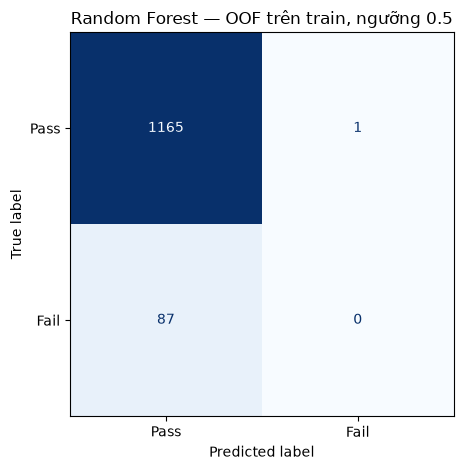

In [9]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
)

initial_threshold = 0.5
pred_rf_baseline = (
    oof_rf_baseline >= initial_threshold
).astype(int)

rf_baseline_metrics = pd.DataFrame(
    {
        "Chỉ số": [
            "Precision — lớp Fail",
            "Recall — lớp Fail",
            "F1 — lớp Fail",
            "ROC-AUC",
            "Average Precision (AP)",
        ],
        "Giá trị": [
            precision_score(
                y_train, pred_rf_baseline, zero_division=0
            ),
            recall_score(
                y_train, pred_rf_baseline, zero_division=0
            ),
            f1_score(
                y_train, pred_rf_baseline, zero_division=0
            ),
            roc_auc_score(y_train, oof_rf_baseline),
            average_precision_score(y_train, oof_rf_baseline),
        ],
    }
)

display(rf_baseline_metrics.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    pred_rf_baseline,
    labels=[0, 1],
    display_labels=["Pass", "Fail"],
    cmap="Blues",
    colorbar=False,
)

plt.title("Random Forest — OOF trên train, ngưỡng 0.5")
plt.tight_layout()
plt.show()

## 5. Phân tích xác suất OOF và ngưỡng cảnh báo

Mô hình trả về xác suất Fail; ngưỡng chuyển xác suất thành cảnh báo.

Kiểm tra ngưỡng trên OOF của train:
- Ngưỡng thấp hơn thường giúp phát hiện thêm Fail.
- Đổi lại, số cảnh báo và nguy cơ báo động giả tăng.
- Thử chọn ngưỡng tối đa hóa F1 cho RF cơ bản.

Đây là phân tích ban đầu, chưa phải kết quả test hoặc kết luận
mô hình đủ điều kiện triển khai doanh nghiệp.

In [10]:
# Kiểm tra các xác suất đang nằm ở đâu
y_rf = y_train.to_numpy()
proba_rf = np.asarray(oof_rf_baseline)

assert proba_rf.shape == y_rf.shape
assert np.isfinite(proba_rf).all()

probability_summary = pd.DataFrame({
    "Nhãn thật": np.where(y_rf == 1, "Fail", "Pass"),
    "Điểm Fail OOF": proba_rf,
})

display(
    probability_summary
    .groupby("Nhãn thật")["Điểm Fail OOF"]
    .describe()
    .round(4)
)

print(f"Điểm cao nhất: {proba_rf.max():.4f}")
print(
    "Số mẫu được cảnh báo ở ngưỡng 0.5:",
    int((proba_rf >= 0.5).sum()),
)

,count,mean,std,min,25%,50%,75%,max
Nhãn thật,,,,,,,,
Fail,87.0,0.1515,0.1022,0.0141,0.0690,0.1350,0.2093,0.4067
Pass,1166.0,0.0864,0.0804,0.0000,0.0293,0.0609,0.1161,0.5118


Điểm cao nhất: 0.5118
Số mẫu được cảnh báo ở ngưỡng 0.5: 1


In [11]:
# Thử các ngưỡng và đếm kết quả
# Xét các điểm dự đoán thực tế, cùng các mốc tham chiếu.
threshold_candidates = np.unique(
    np.r_[0.0, proba_rf, 0.5, 1.0]
)

threshold_rows = []

for threshold in threshold_candidates:
    predicted_fail = proba_rf >= threshold
    actual_fail = y_rf == 1

    tp = int((predicted_fail & actual_fail).sum())
    fp = int((predicted_fail & ~actual_fail).sum())
    fn = int((~predicted_fail & actual_fail).sum())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    threshold_rows.append({
        "Ngưỡng": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Fail phát hiện đúng": tp,
        "Pass cảnh báo nhầm": fp,
        "Fail bỏ sót": fn,
        "Số cảnh báo": tp + fp,
        "Tỷ lệ cảnh báo (%)": 100 * (tp + fp) / len(y_rf),
    })

threshold_table_rf_baseline = pd.DataFrame(threshold_rows)

# Ưu tiên F1 cao nhất.
# Nếu F1 bằng nhau, chọn ngưỡng cao hơn để có quy tắc nhất quán.
ranked_thresholds = threshold_table_rf_baseline.sort_values(
    ["F1", "Ngưỡng"],
    ascending=[False, False],
)

threshold_rf_baseline = float(
    ranked_thresholds.iloc[0]["Ngưỡng"]
)

print(f"Ngưỡng F1 tốt nhất trên OOF: {threshold_rf_baseline:.4f}")

display(ranked_thresholds.head(10).round(4))

print("Kết quả tại ngưỡng 0.5:")
display(
    threshold_table_rf_baseline[
        threshold_table_rf_baseline["Ngưỡng"] == 0.5
    ].round(4)
)

Ngưỡng F1 tốt nhất trên OOF: 0.1777


,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Pass cảnh báo nhầm,Fail bỏ sót,Số cảnh báo,Tỷ lệ cảnh báo (%)
1048,0.1777,0.1897,0.3793,0.2529,33,141,54,174,13.8867
1047,0.1776,0.1886,0.3793,0.2519,33,142,54,175,13.9665
1015,0.1627,0.1787,0.4253,0.2517,37,170,50,207,16.5204
1046,0.1773,0.1875,0.3793,0.2510,33,143,54,176,14.0463
1014,0.1625,0.1779,0.4253,0.2508,37,171,50,208,16.6002
1037,0.1742,0.1838,0.3908,0.2500,34,151,53,185,14.7646
1029,0.1683,0.1813,0.4023,0.2500,35,158,52,193,15.4030
1013,0.1613,0.1770,0.4253,0.2500,37,172,50,209,16.6800
1045,0.1766,0.1864,0.3793,0.2500,33,144,54,177,14.1261
1012,0.1605,0.1762,0.4253,0.2492,37,173,50,210,16.7598


Kết quả tại ngưỡng 0.5:


,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Pass cảnh báo nhầm,Fail bỏ sót,Số cảnh báo,Tỷ lệ cảnh báo (%)
1221,0.5,0.0,0.0,0.0,0,1,87,1,0.0798


Bảng này giúp mình trả lời cụ thể:
“Phát hiện được bao nhiêu mẫu lỗi, bỏ sót bao nhiêu và phải kiểm tra nhầm bao nhiêu mẫu Pass?”

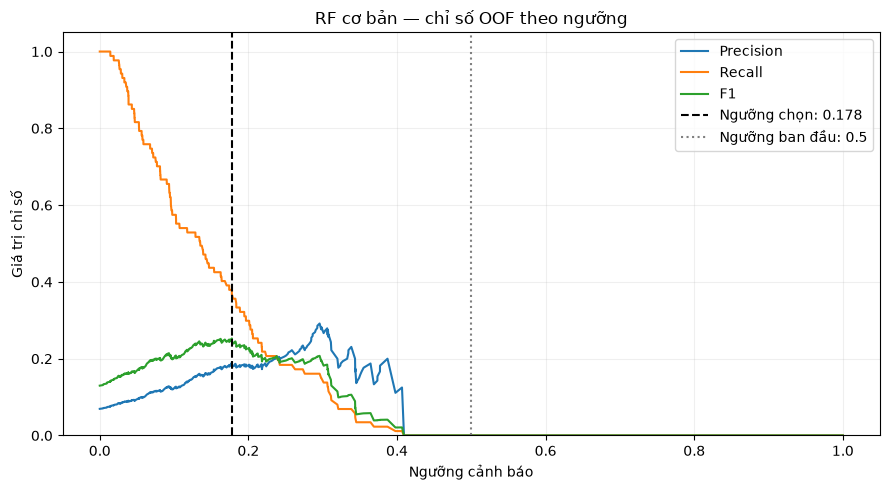

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1"]:
    ax.plot(
        threshold_table_rf_baseline["Ngưỡng"],
        threshold_table_rf_baseline[metric],
        label=metric,
    )

ax.axvline(
    threshold_rf_baseline,
    color="black",
    linestyle="--",
    label=f"Ngưỡng chọn: {threshold_rf_baseline:.3f}",
)

ax.axvline(
    0.5,
    color="gray",
    linestyle=":",
    label="Ngưỡng ban đầu: 0.5",
)

ax.set_title("RF cơ bản — chỉ số OOF theo ngưỡng")
ax.set_xlabel("Ngưỡng cảnh báo")
ax.set_ylabel("Giá trị chỉ số")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

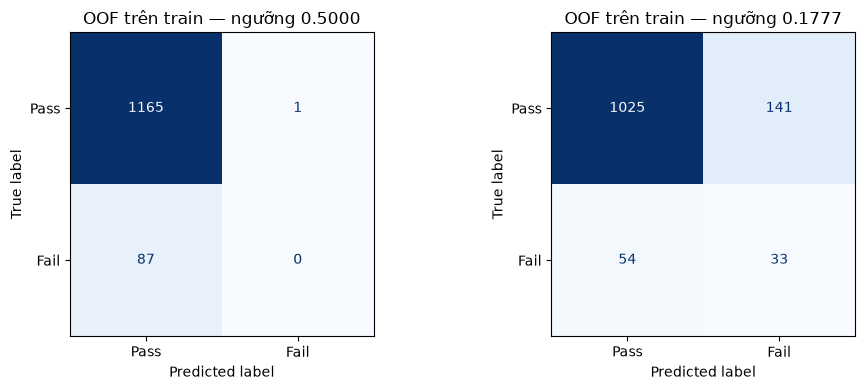

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, threshold in zip(
    axes, [0.5, threshold_rf_baseline]
):
    # Cùng xác suất OOF, nhưng áp dụng hai ngưỡng khác nhau.
    predictions = (
        oof_rf_baseline >= threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        predictions,
        labels=[0, 1],
        display_labels=["Pass", "Fail"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(f"OOF trên train — ngưỡng {threshold:.4f}")

plt.tight_layout()
plt.show()

## 6. Tuning Random Forest

Thử 8 cấu hình bằng 5-fold stratified trên train.

- Giữ 200 cây, class_weight và 40 đặc trưng.
- Thay đổi độ sâu, số mẫu tối thiểu ở lá và max_features.
- Chọn cấu hình theo Average Precision (AP).
- Tiền xử lý được fit lại trong từng fold.
- Chưa dùng test và chưa huấn luyện mô hình cuối.

In [14]:
# Ở bước này mình sẽ dùng GridSearchCV để thử toàn bộ tổ hợp
from sklearn.model_selection import GridSearchCV, ParameterGrid

rf_param_grid = {
    f"{config.STEP_MODEL}__max_depth": [6, None],
    f"{config.STEP_MODEL}__min_samples_leaf": [2, 5],
    f"{config.STEP_MODEL}__max_features": ["sqrt", 0.5],
}

n_candidates = len(list(ParameterGrid(rf_param_grid)))

print("Số cấu hình:", n_candidates)
print("Số lượt fit:", n_candidates * config.N_FOLDS)

rf_search_full = GridSearchCV(
    estimator=build_rf_pipeline(),
    param_grid=rf_param_grid,
    scoring="average_precision",
    cv=cv_rf,
    n_jobs=1,
    refit=False,
    verbose=2,
    error_score="raise",
)

Số cấu hình: 8
Số lượt fit: 40


In [15]:
print("Bắt đầu tuning Random Forest...")
start_time = perf_counter()

# Dùng train thô; Pipeline xử lý dữ liệu bên trong mỗi fold.
rf_search_full.fit(X_train, y_train)

elapsed = perf_counter() - start_time

print(f"\nHoàn thành trong {elapsed:.2f} giây.")
print("Cấu hình được chọn:")
print(rf_search_full.best_params_)
print(f"AP trung bình CV: {rf_search_full.best_score_:.4f}")

rf_tuning_results = pd.DataFrame(
    rf_search_full.cv_results_
)

tuning_view = rf_tuning_results[[
    "rank_test_score",
    f"param_{config.STEP_MODEL}__max_depth",
    f"param_{config.STEP_MODEL}__min_samples_leaf",
    f"param_{config.STEP_MODEL}__max_features",
    "mean_test_score",
    "std_test_score",
]].copy()

tuning_view.columns = [
    "Xếp hạng",
    "Độ sâu tối đa",
    "Mẫu tối thiểu ở lá",
    "max_features",
    "AP trung bình CV",
    "Độ lệch chuẩn AP",
]

# Hiển thị None rõ nghĩa, tránh nhầm với dữ liệu thiếu.
tuning_view["Độ sâu tối đa"] = (
    tuning_view["Độ sâu tối đa"]
    .astype(object)
    .where(
        tuning_view["Độ sâu tối đa"].notna(),
        "Không giới hạn",
    )
)

display(
    tuning_view
    .sort_values("Xếp hạng")
    .reset_index(drop=True)
    .round(4)
)

Bắt đầu tuning Random Forest...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=2; total time=   1.5s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=2; total time=   1.4s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=2; total time=   1.5s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=2; total time=   1.8s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=2; total time=   1.5s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   1.4s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   1.4s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   1.2s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   1.4s

,Xếp hạng,Độ sâu tối đa,Mẫu tối thiểu ở lá,max_features,AP trung bình CV,Độ lệch chuẩn AP
0,1,Không giới hạn,2,0.5,0.2359,0.1020
1,2,6,2,sqrt,0.2184,0.1084
2,3,6,2,0.5,0.2166,0.0702
3,4,Không giới hạn,2,sqrt,0.2113,0.1201
4,5,6,5,0.5,0.2105,0.0719
5,6,Không giới hạn,5,0.5,0.2049,0.0784
6,7,6,5,sqrt,0.1979,0.0792
7,8,Không giới hạn,5,sqrt,0.1927,0.0664


## 7. Tạo OOF cho Random Forest có tuning

Sử dụng cross-validation hai tầng:

- Vòng ngoài: giữ một fold để tạo dự đoán OOF.
- Vòng trong: chọn cấu hình bằng dữ liệu của các fold còn lại.
- Tiền xử lý được fit bên trong Pipeline.
- Mỗi mẫu train nhận một dự đoán khi chưa tham gia học hoặc tuning
  trong lượt tương ứng.
- Chưa sử dụng tập test.

Kết quả được lưu vào biến oof_rf_tuned.

In [16]:
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid,
)
from sklearn.metrics import average_precision_score
from time import perf_counter

# Dùng cùng cách chia vòng ngoài với RF cơ bản.
outer_cv_rf = StratifiedKFold(
    n_splits=config.N_FOLDS,
    shuffle=True,
    random_state=config.SEED,
)

# Chỉ dùng để tuning bên trong phần được phép học.
inner_cv_rf = StratifiedKFold(
    n_splits=config.N_FOLDS,
    shuffle=True,
    random_state=config.SEED,
)

# Mỗi vị trí sẽ nhận xác suất OOF của đúng mẫu tương ứng.
oof_rf_tuned = np.full(len(y_train), np.nan)
oof_coverage_rf = np.zeros(len(y_train), dtype=int)

rf_outer_results = []
rf_params_by_fold = []

n_candidates = len(list(ParameterGrid(rf_param_grid)))
n_fits = config.N_FOLDS * (
    n_candidates * config.N_FOLDS + 1
)

print(f"Tổng số lượt fit dự kiến: {n_fits}")
start_time = perf_counter()

for fold_number, (learn_idx, holdout_idx) in enumerate(
    outer_cv_rf.split(X_train, y_train),
    start=1,
):
    print(f"\nBắt đầu fold ngoài {fold_number}/{config.N_FOLDS}...")

    # Tách bằng vị trí; đặc trưng và nhãn dùng cùng chỉ số.
    X_learn = X_train.iloc[learn_idx]
    y_learn = y_train.iloc[learn_idx]

    X_holdout = X_train.iloc[holdout_idx]
    y_holdout = y_train.iloc[holdout_idx]

    fold_search = GridSearchCV(
        estimator=build_rf_pipeline(),
        param_grid=rf_param_grid,
        scoring="average_precision",
        cv=inner_cv_rf,
        n_jobs=1,
        refit=True,
        error_score="raise",
    )

    # Chỉ học và tuning trên X_learn, y_learn.
    fold_search.fit(X_learn, y_learn)

    # refit=True đã fit cấu hình được chọn trên toàn bộ X_learn.
    # X_holdout chưa tham gia quá trình này.
    fail_column = int(
        np.flatnonzero(fold_search.classes_ == config.FAIL)[0]
    )

    holdout_proba = fold_search.predict_proba(
        X_holdout
    )[:, fail_column]

    oof_rf_tuned[holdout_idx] = holdout_proba
    oof_coverage_rf[holdout_idx] += 1

    holdout_ap = average_precision_score(
        y_holdout, holdout_proba
    )

    rf_outer_results.append({
        "Fold ngoài": fold_number,
        "Số mẫu học": len(y_learn),
        "Số mẫu giữ lại": len(y_holdout),
        "Fail trong phần giữ lại": int(y_holdout.sum()),
        "AP fold giữ lại": holdout_ap,
    })

    rf_params_by_fold.append(fold_search.best_params_.copy())

    print("Cấu hình chọn:", fold_search.best_params_)
    print(f"AP trên fold giữ lại: {holdout_ap:.4f}")

# Kiểm tra mỗi mẫu đã được dự đoán đúng một lần.
assert (oof_coverage_rf == 1).all()
assert np.isfinite(oof_rf_tuned).all()
assert ((oof_rf_tuned >= 0) & (oof_rf_tuned <= 1)).all()

print(f"\nHoàn thành trong {perf_counter() - start_time:.2f} giây.")
print("Số xác suất OOF:", len(oof_rf_tuned))

rf_outer_summary = pd.DataFrame(rf_outer_results)
display(rf_outer_summary.round(4))

Tổng số lượt fit dự kiến: 205

Bắt đầu fold ngoài 1/5...
Cấu hình chọn: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}
AP trên fold giữ lại: 0.3414

Bắt đầu fold ngoài 2/5...
Cấu hình chọn: {'model__max_depth': 6, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2}
AP trên fold giữ lại: 0.1199

Bắt đầu fold ngoài 3/5...
Cấu hình chọn: {'model__max_depth': 6, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}
AP trên fold giữ lại: 0.2261

Bắt đầu fold ngoài 4/5...
Cấu hình chọn: {'model__max_depth': 6, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2}
AP trên fold giữ lại: 0.1430

Bắt đầu fold ngoài 5/5...
Cấu hình chọn: {'model__max_depth': 6, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2}
AP trên fold giữ lại: 0.1619

Hoàn thành trong 173.45 giây.
Số xác suất OOF: 1253


,Fold ngoài,Số mẫu học,Số mẫu giữ lại,Fail trong phần giữ lại,AP fold giữ lại
0,1,1002,251,17,0.3414
1,2,1002,251,18,0.1199
2,3,1002,251,18,0.2261
3,4,1003,250,17,0.1430
4,5,1003,250,17,0.1619


In [17]:
# so sánh với RF cơ bản
from sklearn.metrics import roc_auc_score

rf_oof_comparison = pd.DataFrame({
    "Quy trình": [
        "RF cơ bản",
        "RF có tuning trong từng fold",
    ],
    "AP trên OOF gộp": [
        average_precision_score(y_train, oof_rf_baseline),
        average_precision_score(y_train, oof_rf_tuned),
    ],
    "ROC-AUC trên OOF gộp": [
        roc_auc_score(y_train, oof_rf_baseline),
        roc_auc_score(y_train, oof_rf_tuned),
    ],
})

display(rf_oof_comparison.round(4))

print(
    "AP trung bình các fold ngoài:",
    round(rf_outer_summary["AP fold giữ lại"].mean(), 4),
)

,Quy trình,AP trên OOF gộp,ROC-AUC trên OOF gộp
0,RF cơ bản,0.1530,0.7083
1,RF có tuning trong từng fold,0.1601,0.7305


AP trung bình các fold ngoài: 0.1984


## 8. Chọn ngưỡng cho Random Forest có tuning

Sử dụng oof_rf_tuned và nhãn train để thử các ngưỡng cảnh báo.

- Chọn ngưỡng tối đa hóa F1.
- Nếu F1 bằng nhau, ưu tiên ngưỡng cao hơn.
- So sánh với RF cơ bản, mỗi quy trình dùng ngưỡng riêng.
- Báo cáo số Fail phát hiện, Fail bỏ sót và Pass cảnh báo nhầm.

Các chỉ số tại ngưỡng được chọn phục vụ lựa chọn phương pháp,
chưa phải kết quả đánh giá độc lập trên test.

In [18]:
# chọn ngưỡng 
required_variables = [
    "y_train",
    "oof_rf_tuned",
    "threshold_rf_baseline",
    "threshold_table_rf_baseline",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy lại các cell tạo những biến này trước."
    )

# Hàm này có thể tái sử dụng cho XGBoost sau này.
def build_threshold_table(y_true, probabilities):
    y = np.asarray(y_true)
    proba = np.asarray(probabilities, dtype=float)

    assert y.shape == proba.shape
    assert np.isfinite(proba).all()
    assert ((proba >= 0) & (proba <= 1)).all()

    actual_fail = y == config.FAIL
    thresholds = np.unique(np.r_[0.0, proba, 0.5, 1.0])
    rows = []

    for threshold in thresholds:
        predicted_fail = proba >= threshold

        tp = int((predicted_fail & actual_fail).sum())
        fp = int((predicted_fail & ~actual_fail).sum())
        fn = int((~predicted_fail & actual_fail).sum())
        tn = int((~predicted_fail & ~actual_fail).sum())

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        denominator = 2 * tp + fp + fn
        f1 = 2 * tp / denominator if denominator else 0.0

        rows.append({
            "Ngưỡng": float(threshold),
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Fail phát hiện đúng": tp,
            "Pass cảnh báo nhầm": fp,
            "Fail bỏ sót": fn,
            "Pass cho qua đúng": tn,
            "Số cảnh báo": tp + fp,
            "Tỷ lệ cảnh báo (%)": 100 * (tp + fp) / len(y),
        })

    return pd.DataFrame(rows)

threshold_table_rf_tuned = build_threshold_table(
    y_train, oof_rf_tuned
)

ranked_thresholds_rf_tuned = (
    threshold_table_rf_tuned
    .sort_values(
        ["F1", "Ngưỡng"],
        ascending=[False, False],
    )
)

best_rf_tuned_row = ranked_thresholds_rf_tuned.iloc[0]
threshold_rf_tuned = float(best_rf_tuned_row["Ngưỡng"])

print(f"Ngưỡng RF cơ bản: {threshold_rf_baseline:.4f}")
print(f"Ngưỡng RF có tuning: {threshold_rf_tuned:.4f}")

display(ranked_thresholds_rf_tuned.head(10).round(4))

Ngưỡng RF cơ bản: 0.1777
Ngưỡng RF có tuning: 0.2870


,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Pass cảnh báo nhầm,Fail bỏ sót,Pass cho qua đúng,Số cảnh báo,Tỷ lệ cảnh báo (%)
1012,0.2870,0.1694,0.4713,0.2492,41,201,46,965,242,19.3136
1140,0.3882,0.2193,0.2874,0.2488,25,89,62,1077,114,9.0982
1011,0.2868,0.1687,0.4713,0.2485,41,202,46,964,243,19.3935
1010,0.2862,0.1680,0.4713,0.2477,41,203,46,963,244,19.4733
1139,0.3873,0.2174,0.2874,0.2475,25,90,62,1076,115,9.1780
1074,0.3296,0.1833,0.3793,0.2472,33,147,54,1019,180,14.3655
993,0.2779,0.1648,0.4943,0.2471,43,218,44,948,261,20.8300
1009,0.2855,0.1673,0.4713,0.2470,41,204,46,962,245,19.5531
1017,0.2915,0.1688,0.4598,0.2469,40,197,47,969,237,18.9146
984,0.2708,0.1630,0.5057,0.2465,44,226,43,940,270,21.5483


In [19]:
# so sánh keeys quả cảnh báo
best_rf_baseline_row = threshold_table_rf_baseline[
    threshold_table_rf_baseline["Ngưỡng"]
    == threshold_rf_baseline
].iloc[0]

rf_threshold_comparison = pd.DataFrame([
    best_rf_baseline_row.to_dict(),
    best_rf_tuned_row.to_dict(),
])

rf_threshold_comparison.insert(
    0,
    "Quy trình",
    ["RF cơ bản", "RF có tuning"],
)

display(
    rf_threshold_comparison[[
        "Quy trình",
        "Ngưỡng",
        "Precision",
        "Recall",
        "F1",
        "Fail phát hiện đúng",
        "Pass cảnh báo nhầm",
        "Fail bỏ sót",
        "Số cảnh báo",
    ]].round(4)
)

,Quy trình,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Pass cảnh báo nhầm,Fail bỏ sót,Số cảnh báo
0,RF cơ bản,0.1777,0.1897,0.3793,0.2529,33.0,141.0,54.0,174.0
1,RF có tuning,0.2870,0.1694,0.4713,0.2492,41.0,201.0,46.0,242.0


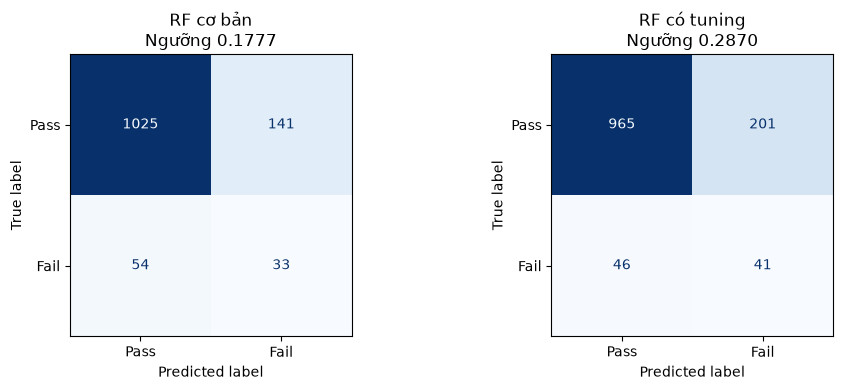

In [20]:
# vẽ 2 ma trận để đối chiếu
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

settings = [
    ("RF cơ bản", oof_rf_baseline, threshold_rf_baseline),
    ("RF có tuning", oof_rf_tuned, threshold_rf_tuned),
]

for ax, (name, probabilities, threshold) in zip(axes, settings):
    predictions = (
        np.asarray(probabilities) >= threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        predictions,
        labels=[0, 1],
        display_labels=["Pass", "Fail"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(f"{name}\nNgưỡng {threshold:.4f}")

plt.tight_layout()
plt.show()

## 9. Phân tích ngưỡng theo yêu cầu vận hành

So sánh RF cơ bản và RF có tuning bằng các xác suất OOF trên train.

Hai cách đặt yêu cầu:
- Recall tối thiểu: tìm ngưỡng tạo ít cảnh báo nhất nhưng vẫn đạt Recall yêu cầu.
- Giới hạn kiểm tra: tìm ngưỡng bắt được nhiều Fail nhất mà không vượt số mẫu được phép cảnh báo.

Các mức Recall và giới hạn kiểm tra dưới đây là kịch bản minh họa,
chưa phải yêu cầu thực tế của doanh nghiệp.

Chưa sử dụng tập test và chưa chốt ngưỡng triển khai.

In [21]:
# chuẩn bị lại bảng ngưỡng của 2 mô hình
import numpy as np
import pandas as pd

required_variables = [
    "y_train",
    "oof_rf_baseline",
    "oof_rf_tuned",
    "build_threshold_table",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

# Dùng lại hàm đã tạo ở bước 8.
# Không fit lại mô hình.
rf_operating_tables = {
    "RF cơ bản": build_threshold_table(
        y_train, oof_rf_baseline
    ),
    "RF có tuning": build_threshold_table(
        y_train, oof_rf_tuned
    ),
}

# Các cột sẽ hiển thị để đối chiếu.
operating_columns = [
    "Mô hình",
    "Yêu cầu",
    "Ngưỡng",
    "Precision",
    "Recall",
    "F1",
    "Fail phát hiện đúng",
    "Fail bỏ sót",
    "Pass cảnh báo nhầm",
    "Số cảnh báo",
    "Tỷ lệ cảnh báo (%)",
]

print("Đã chuẩn bị bảng ngưỡng cho hai RF.")
print("Số mẫu train:", len(y_train))
print("Không huấn luyện lại và không dùng tập test.")

Đã chuẩn bị bảng ngưỡng cho hai RF.
Số mẫu train: 1253
Không huấn luyện lại và không dùng tập test.


* Đặt yêu cầu về Recall
* Chúng ta thử ba kịch bản:
- Yêu cầu minh họa----	Câu hỏi cần trả lời
- Recall ≥ 50%	---    Muốn bắt được ít nhất một nửa số Fail thì cần kiểm tra bao nhiêu sản phẩm?
- Recall ≥ 70%	---    Muốn bắt được ít nhất 70% số Fail thì cảnh báo nhầm bao nhiêu Pass?
- Recall ≥ 90%	---    Muốn bỏ sót rất ít Fail thì khối lượng kiểm tra tăng đến đâu?

In [22]:
recall_targets = [0.50, 0.70, 0.90]
recall_rows = []

for model_name, table in rf_operating_tables.items():
    for target in recall_targets:

        # Chỉ giữ những ngưỡng đạt Recall yêu cầu.
        eligible = table[
            table["Recall"] >= target
        ]

        if eligible.empty:
            raise ValueError(
                f"{model_name}: không có ngưỡng đạt Recall {target:.0%}."
            )

        # Trong các ngưỡng đạt yêu cầu:
        # chọn ngưỡng tạo ít cảnh báo nhất.
        # Nếu bằng nhau, chọn ngưỡng cao hơn.
        selected = eligible.sort_values(
            ["Số cảnh báo", "Ngưỡng"],
            ascending=[True, False],
        ).iloc[0]

        recall_rows.append({
            "Mô hình": model_name,
            "Yêu cầu": f"Recall ≥ {target:.0%}",
            **selected.to_dict(),
        })

rf_recall_scenarios = pd.DataFrame(recall_rows)

display(
    rf_recall_scenarios[operating_columns]
    .round(4)
)

,Mô hình,Yêu cầu,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,RF cơ bản,Recall ≥ 50%,0.1350,0.1588,0.5057,0.2418,44.0,43.0,233.0,277.0,22.1069
1,RF cơ bản,Recall ≥ 70%,0.0810,0.1180,0.7011,0.2020,61.0,26.0,456.0,517.0,41.2610
2,RF cơ bản,Recall ≥ 90%,0.0369,0.0892,0.9080,0.1624,79.0,8.0,807.0,886.0,70.7103
3,RF có tuning,Recall ≥ 50%,0.2708,0.1630,0.5057,0.2465,44.0,43.0,226.0,270.0,21.5483
4,RF có tuning,Recall ≥ 70%,0.1904,0.1386,0.7011,0.2315,61.0,26.0,379.0,440.0,35.1157
5,RF có tuning,Recall ≥ 90%,0.1001,0.0938,0.9080,0.1701,79.0,8.0,763.0,842.0,67.1987


In [23]:
# Đặt giới hạn số sản phẩm được kiểm tra
budget_targets = [0.05, 0.10, 0.20]
budget_rows = []

for model_name, table in rf_operating_tables.items():
    for budget in budget_targets:

        # Làm tròn xuống để không vượt giới hạn.
        max_alerts = int(
            np.floor(budget * len(y_train))
        )

        eligible = table[
            table["Số cảnh báo"] <= max_alerts
        ]

        if eligible.empty:
            raise ValueError(
                f"{model_name}: chưa có ngưỡng phù hợp "
                f"với giới hạn {max_alerts} cảnh báo."
            )

        # Ưu tiên bắt được nhiều Fail nhất.
        # Nếu Recall bằng nhau, chọn ít cảnh báo hơn.
        selected = eligible.sort_values(
            ["Recall", "Số cảnh báo", "Ngưỡng"],
            ascending=[False, True, False],
        ).iloc[0]

        budget_rows.append({
            "Mô hình": model_name,
            "Yêu cầu": (
                f"Kiểm tra ≤ {budget:.0%} "
                f"(≤ {max_alerts} mẫu)"
            ),
            **selected.to_dict(),
        })

rf_budget_scenarios = pd.DataFrame(budget_rows)

display(
    rf_budget_scenarios[operating_columns]
    .round(4)
)

,Mô hình,Yêu cầu,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,RF cơ bản,Kiểm tra ≤ 5% (≤ 62 mẫu),0.2958,0.2917,0.1609,0.2074,14.0,73.0,34.0,48.0,3.8308
1,RF cơ bản,Kiểm tra ≤ 10% (≤ 125 mẫu),0.2126,0.1849,0.2529,0.2136,22.0,65.0,97.0,119.0,9.4972
2,RF cơ bản,Kiểm tra ≤ 20% (≤ 250 mẫu),0.1438,0.1613,0.4598,0.2388,40.0,47.0,208.0,248.0,19.7925
3,RF có tuning,Kiểm tra ≤ 5% (≤ 62 mẫu),0.4597,0.2295,0.1609,0.1892,14.0,73.0,47.0,61.0,4.8683
4,RF có tuning,Kiểm tra ≤ 10% (≤ 125 mẫu),0.3882,0.2193,0.2874,0.2488,25.0,62.0,89.0,114.0,9.0982
5,RF có tuning,Kiểm tra ≤ 20% (≤ 250 mẫu),0.2870,0.1694,0.4713,0.2492,41.0,46.0,201.0,242.0,19.3136


## 10. XGBoost cơ bản và dự đoán OOF

XGBoost xây dựng các cây theo trình tự; cây sau bổ sung để cải thiện
kết quả dự đoán của các cây trước.

Cấu hình ban đầu:
- 200 vòng boosting, mỗi vòng thêm một cây trong cấu hình này.
- Độ sâu tối đa của cây: 3.
- Learning rate: 0.05.
- Xử lý mất cân bằng bằng scale_pos_weight.
- Dùng cùng cách chia 5-fold như RF.

Trong mỗi fold:
- Tính trọng số lớp bằng phần dữ liệu học.
- Fit lại toàn bộ tiền xử lý và mô hình trên phần dữ liệu học.
- Dự đoán phần giữ lại để tạo OOF.

Chưa tuning, chưa dùng early stopping và chưa đánh giá test.

In [24]:
# xây dựng pipeline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from time import perf_counter
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

import config
from src.preprocess import build_preprocessor

if "X_train" not in globals() or "y_train" not in globals():
    raise RuntimeError(
        "Hãy chạy cell đọc dữ liệu và chia train/test trước."
    )

assert X_train.index.equals(y_train.index)


def build_xgb_pipeline(fail_weight):
    preprocessor = build_preprocessor(
        k_features=config.K_FEATURES
    )

    model = XGBClassifier(
        # n_estimators=200:	200 vòng boosting; khác với khái niệm epoch của mạng neural
        n_estimators=200,
        # max_depth=3	Giới hạn độ sâu mỗi cây
        max_depth=3,
        # learning_rate=0.05:	Điều chỉnh mức đóng góp của mỗi cây mới
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        # scale_pos_weight	Tăng trọng số lớp Fail khi học
        scale_pos_weight=fail_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device="cpu",
        random_state=config.SEED,
        n_jobs=4,
    )

    return Pipeline(
        list(preprocessor.steps)
        + [(config.STEP_MODEL, model)]
    )


print("Đã tạo hàm xây dựng Pipeline XGBoost.")

Đã tạo hàm xây dựng Pipeline XGBoost.


In [25]:
# Chạy 5-fold để tạo OOF
# Cùng cách chia fold với RF.
cv_xgb = StratifiedKFold(
    n_splits=config.N_FOLDS,
    shuffle=True,
    random_state=config.SEED,
)

oof_xgb_baseline = np.full(len(y_train), np.nan)
oof_coverage_xgb = np.zeros(len(y_train), dtype=int)

xgb_fold_rows = []
start_time = perf_counter()

for fold_number, (learn_idx, holdout_idx) in enumerate(
    cv_xgb.split(X_train, y_train),
    start=1,
):
    print(f"Đang chạy fold {fold_number}/{config.N_FOLDS}...")

    X_learn = X_train.iloc[learn_idx]
    y_learn = y_train.iloc[learn_idx]

    X_holdout = X_train.iloc[holdout_idx]

    # Chỉ tính trọng số từ phần được phép học.
    n_pass = int((y_learn == config.PASS).sum())
    n_fail = int((y_learn == config.FAIL).sum())

    if n_pass == 0 or n_fail == 0:
        raise ValueError("Phần học phải có đủ hai lớp.")

    fail_weight = n_pass / n_fail

    pipeline = build_xgb_pipeline(fail_weight)

    # Dùng dữ liệu thô: Pipeline tự học tiền xử lý.
    pipeline.fit(X_learn, y_learn)

    fail_column = int(
        np.flatnonzero(pipeline.classes_ == config.FAIL)[0]
    )

    oof_xgb_baseline[holdout_idx] = (
        pipeline.predict_proba(X_holdout)[:, fail_column]
    )

    oof_coverage_xgb[holdout_idx] += 1

    xgb_fold_rows.append({
        "Fold": fold_number,
        "Số mẫu học": len(learn_idx),
        "Pass trong phần học": n_pass,
        "Fail trong phần học": n_fail,
        "scale_pos_weight": fail_weight,
        "Số mẫu giữ lại": len(holdout_idx),
    })

# Mỗi mẫu phải nhận đúng một dự đoán OOF.
assert (oof_coverage_xgb == 1).all()
assert np.isfinite(oof_xgb_baseline).all()
assert (
    (oof_xgb_baseline >= 0)
    & (oof_xgb_baseline <= 1)
).all()

xgb_fold_summary = pd.DataFrame(xgb_fold_rows)

display(xgb_fold_summary.round(4))

print(f"Hoàn thành trong {perf_counter() - start_time:.2f} giây.")
print("Số điểm dự đoán OOF:", len(oof_xgb_baseline))

Đang chạy fold 1/5...
Đang chạy fold 2/5...
Đang chạy fold 3/5...
Đang chạy fold 4/5...
Đang chạy fold 5/5...


,Fold,Số mẫu học,Pass trong phần học,Fail trong phần học,scale_pos_weight,Số mẫu giữ lại
0,1,1002,932,70,13.3143,251
1,2,1002,933,69,13.5217,251
2,3,1002,933,69,13.5217,251
3,4,1003,933,70,13.3286,250
4,5,1003,933,70,13.3286,250


Hoàn thành trong 1.23 giây.
Số điểm dự đoán OOF: 1253


,Mô hình,Ngưỡng,AP trên OOF,ROC-AUC trên OOF,Precision,Recall,F1,Số cảnh báo
0,XGBoost cơ bản,0.5,0.1553,0.6956,0.1963,0.2414,0.2165,107


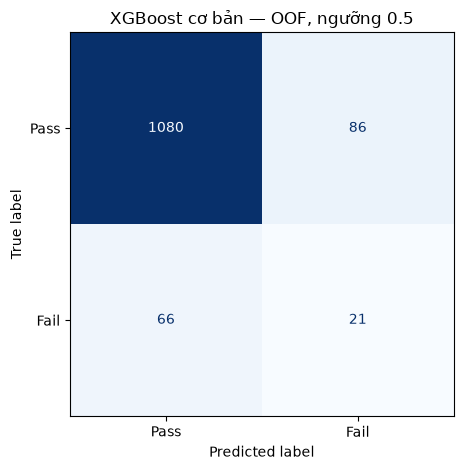

In [26]:
# Xem kết quả ban đầu ở ngưỡng 0,5
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)

initial_threshold_xgb = 0.5

pred_xgb_baseline = np.where(
    oof_xgb_baseline >= initial_threshold_xgb,
    config.FAIL,
    config.PASS,
)

xgb_baseline_summary = pd.DataFrame([{
    "Mô hình": "XGBoost cơ bản",
    "Ngưỡng": initial_threshold_xgb,
    "AP trên OOF": average_precision_score(
        y_train, oof_xgb_baseline
    ),
    "ROC-AUC trên OOF": roc_auc_score(
        y_train, oof_xgb_baseline
    ),
    "Precision": precision_score(
        y_train, pred_xgb_baseline,
        pos_label=config.FAIL, zero_division=0,
    ),
    "Recall": recall_score(
        y_train, pred_xgb_baseline,
        pos_label=config.FAIL, zero_division=0,
    ),
    "F1": f1_score(
        y_train, pred_xgb_baseline,
        pos_label=config.FAIL, zero_division=0,
    ),
    "Số cảnh báo": int(
        (pred_xgb_baseline == config.FAIL).sum()
    ),
}])

display(xgb_baseline_summary.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    pred_xgb_baseline,
    labels=[config.PASS, config.FAIL],
    display_labels=["Pass", "Fail"],
    cmap="Blues",
    colorbar=False,
)

plt.title("XGBoost cơ bản — OOF, ngưỡng 0.5")
plt.tight_layout()
plt.show()

## 11. Phân tích ngưỡng XGBoost và so sánh với RF

Sử dụng dự đoán OOF trên train của ba quy trình:
- RF cơ bản.
- RF có tuning.
- XGBoost cơ bản.

So sánh theo:
1. Ngưỡng tối đa hóa F1 — dùng làm mốc tham khảo.
2. Recall tối thiểu: 50%, 70%, 90%.
3. Giới hạn kiểm tra: 5%, 10%, 20% tổng sản phẩm.

Định hướng nghiệp vụ: ưu tiên phát hiện Fail, đồng thời theo dõi
số cảnh báo nhầm và khối lượng kiểm tra lại.

Đây là phân tích lựa chọn trên train, chưa đánh giá test.

In [27]:
# chuẩn bị bảng ngưỡng và so sánh theo F1
import numpy as np
import pandas as pd
from IPython.display import display

required_variables = [
    "y_train",
    "oof_rf_baseline",
    "oof_rf_tuned",
    "oof_xgb_baseline",
    "build_threshold_table",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

# Chỉ tính bảng chỉ số từ OOF, không fit lại mô hình.
comparison_threshold_tables = {
    "RF cơ bản": build_threshold_table(
        y_train, oof_rf_baseline
    ),
    "RF có tuning": build_threshold_table(
        y_train, oof_rf_tuned
    ),
    "XGBoost cơ bản": build_threshold_table(
        y_train, oof_xgb_baseline
    ),
}

threshold_table_xgb_baseline = (
    comparison_threshold_tables["XGBoost cơ bản"]
)

# Các cột dùng chung cho những bảng kết quả.
threshold_result_columns = [
    "Ngưỡng",
    "Precision",
    "Recall",
    "F1",
    "Fail phát hiện đúng",
    "Fail bỏ sót",
    "Pass cảnh báo nhầm",
    "Số cảnh báo",
    "Tỷ lệ cảnh báo (%)",
]

f1_comparison_rows = []

for model_name, table in comparison_threshold_tables.items():
    selected = table.sort_values(
        ["F1", "Ngưỡng"],
        ascending=[False, False],
    ).iloc[0]

    f1_comparison_rows.append({
        "Mô hình": model_name,
        **selected.to_dict(),
    })

    if model_name == "XGBoost cơ bản":
        threshold_xgb_baseline_f1 = float(
            selected["Ngưỡng"]
        )

comparison_f1 = pd.DataFrame(f1_comparison_rows)

display(
    comparison_f1[
        ["Mô hình"] + threshold_result_columns
    ].round(4)
)

print(
    "Ngưỡng F1 tham khảo của XGBoost:",
    f"{threshold_xgb_baseline_f1:.6f}",
)

,Mô hình,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,RF cơ bản,0.1777,0.1897,0.3793,0.2529,33.0,54.0,141.0,174.0,13.8867
1,RF có tuning,0.2870,0.1694,0.4713,0.2492,41.0,46.0,201.0,242.0,19.3136
2,XGBoost cơ bản,0.3570,0.1799,0.3908,0.2464,34.0,53.0,155.0,189.0,15.0838


Ngưỡng F1 tham khảo của XGBoost: 0.357015


In [28]:
# so sánh ở cùng yêu cầu Recall
# trả lời cho câu hỏi : Muốn đạt Recall tối thiểu như nhau, mô hình nào cần ít lượt kiểm tra hơn?
recall_targets = [0.50, 0.70, 0.90]
recall_comparison_rows = []

for model_name, table in comparison_threshold_tables.items():
    for target in recall_targets:
        eligible = table[
            table["Recall"] >= target
        ]

        if eligible.empty:
            raise ValueError(
                f"{model_name}: không có ngưỡng "
                f"đạt Recall {target:.0%}."
            )

        # Đạt Recall yêu cầu, rồi giảm số cảnh báo.
        selected = eligible.sort_values(
            ["Số cảnh báo", "Ngưỡng"],
            ascending=[True, False],
        ).iloc[0]

        recall_comparison_rows.append({
            "Mô hình": model_name,
            "Yêu cầu": f"Recall ≥ {target:.0%}",
            **selected.to_dict(),
        })

comparison_recall = pd.DataFrame(
    recall_comparison_rows
)

display(
    comparison_recall[
        ["Yêu cầu", "Mô hình"]
        + threshold_result_columns
    ]
    .sort_values(["Yêu cầu", "Số cảnh báo"])
    .reset_index(drop=True)
    .round(4)
)

,Yêu cầu,Mô hình,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,Recall ≥ 50%,RF có tuning,0.2708,0.1630,0.5057,0.2465,44.0,43.0,226.0,270.0,21.5483
1,Recall ≥ 50%,RF cơ bản,0.1350,0.1588,0.5057,0.2418,44.0,43.0,233.0,277.0,22.1069
2,Recall ≥ 50%,XGBoost cơ bản,0.1839,0.1302,0.5057,0.2071,44.0,43.0,294.0,338.0,26.9753
3,Recall ≥ 70%,RF có tuning,0.1904,0.1386,0.7011,0.2315,61.0,26.0,379.0,440.0,35.1157
4,Recall ≥ 70%,RF cơ bản,0.0810,0.1180,0.7011,0.2020,61.0,26.0,456.0,517.0,41.2610
5,Recall ≥ 70%,XGBoost cơ bản,0.0795,0.1072,0.7011,0.1860,61.0,26.0,508.0,569.0,45.4110
6,Recall ≥ 90%,RF có tuning,0.1001,0.0938,0.9080,0.1701,79.0,8.0,763.0,842.0,67.1987
7,Recall ≥ 90%,XGBoost cơ bản,0.0315,0.0909,0.9080,0.1653,79.0,8.0,790.0,869.0,69.3536
8,Recall ≥ 90%,RF cơ bản,0.0369,0.0892,0.9080,0.1624,79.0,8.0,807.0,886.0,70.7103


In [29]:
# so sánh ở cùng giới hạn kiểm tra
# Trả lời cho câu hỏi: Nếu chỉ được kiểm tra một lượng sản phẩm nhất định, mô hình nào phát hiện nhiều Fail hơn?
budget_targets = [0.05, 0.10, 0.20]
budget_comparison_rows = []

for model_name, table in comparison_threshold_tables.items():
    for budget in budget_targets:
        max_alerts = int(
            np.floor(budget * len(y_train))
        )

        eligible = table[
            table["Số cảnh báo"] <= max_alerts
        ]

        if eligible.empty:
            raise ValueError(
                f"{model_name}: không có ngưỡng "
                f"phù hợp giới hạn {max_alerts} cảnh báo."
            )

        # Trong giới hạn kiểm tra:
        # ưu tiên Recall cao nhất.
        # Nếu bằng nhau, ưu tiên ít cảnh báo hơn.
        selected = eligible.sort_values(
            ["Recall", "Số cảnh báo", "Ngưỡng"],
            ascending=[False, True, False],
        ).iloc[0]

        budget_comparison_rows.append({
            "Mô hình": model_name,
            "Yêu cầu": (
                f"Kiểm tra ≤ {budget:.0%} "
                f"(≤ {max_alerts} mẫu)"
            ),
            **selected.to_dict(),
        })

comparison_budget = pd.DataFrame(
    budget_comparison_rows
)

display(
    comparison_budget[
        ["Yêu cầu", "Mô hình"]
        + threshold_result_columns
    ]
    .sort_values(
        ["Yêu cầu", "Recall", "Số cảnh báo"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
    .round(4)
)


,Yêu cầu,Mô hình,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,Kiểm tra ≤ 10% (≤ 125 mẫu),RF có tuning,0.3882,0.2193,0.2874,0.2488,25.0,62.0,89.0,114.0,9.0982
1,Kiểm tra ≤ 10% (≤ 125 mẫu),RF cơ bản,0.2126,0.1849,0.2529,0.2136,22.0,65.0,97.0,119.0,9.4972
2,Kiểm tra ≤ 10% (≤ 125 mẫu),XGBoost cơ bản,0.4722,0.1760,0.2529,0.2075,22.0,65.0,103.0,125.0,9.9761
3,Kiểm tra ≤ 20% (≤ 250 mẫu),RF có tuning,0.2870,0.1694,0.4713,0.2492,41.0,46.0,201.0,242.0,19.3136
4,Kiểm tra ≤ 20% (≤ 250 mẫu),RF cơ bản,0.1438,0.1613,0.4598,0.2388,40.0,47.0,208.0,248.0,19.7925
5,Kiểm tra ≤ 20% (≤ 250 mẫu),XGBoost cơ bản,0.2654,0.1526,0.4368,0.2262,38.0,49.0,211.0,249.0,19.8723
6,Kiểm tra ≤ 5% (≤ 62 mẫu),XGBoost cơ bản,0.6453,0.2667,0.1839,0.2177,16.0,71.0,44.0,60.0,4.7885
7,Kiểm tra ≤ 5% (≤ 62 mẫu),RF cơ bản,0.2958,0.2917,0.1609,0.2074,14.0,73.0,34.0,48.0,3.8308
8,Kiểm tra ≤ 5% (≤ 62 mẫu),RF có tuning,0.4597,0.2295,0.1609,0.1892,14.0,73.0,47.0,61.0,4.8683


## 12. Tuning XGBoost

Thử 8 cấu hình bằng 5-fold stratified trên train.

Giữ nguyên:
- 200 vòng boosting.
- Learning rate: 0.05.
- Subsample: 0.8.
- Pipeline tiền xử lý và 40 đặc trưng.

Thay đổi:
- max_depth.
- min_child_weight.
- colsample_bytree.

Chọn cấu hình theo Average Precision (AP) trung bình CV.
Trọng số lớp Fail được tính lại từ phần học của từng fold.
Tiền xử lý được fit riêng trong từng fold.

Chưa tạo OOF sau tuning và chưa đánh giá test.

In [30]:
# tạo pipeline tự tính trọng số sau từng lượt học
import numpy as np
import pandas as pd

from IPython.display import display
from time import perf_counter

from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid,
)

import config
from src.preprocess import build_preprocessor

if "X_train" not in globals() or "y_train" not in globals():
    raise RuntimeError(
        "Hãy chạy cell đọc dữ liệu và chia train/test trước."
    )


class AutoWeightedXGBClassifier(XGBClassifier):
    """Tính trọng số lớp từ nhãn được đưa vào mỗi lần fit."""

    def fit(self, X, y, **fit_params):
        labels = np.asarray(y)

        n_pass = int((labels == config.PASS).sum())
        n_fail = int((labels == config.FAIL).sum())

        if n_pass == 0 or n_fail == 0:
            raise ValueError(
                "Phần học phải có đủ hai lớp Pass và Fail."
            )

        self.set_params(
            scale_pos_weight=n_pass / n_fail
        )

        return super().fit(X, y, **fit_params)


def build_xgb_tuning_pipeline():
    preprocessor = build_preprocessor(
        k_features=config.K_FEATURES
    )

    model = AutoWeightedXGBClassifier(
        n_estimators=200,
        max_depth=3,
        min_child_weight=1,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device="cpu",
        random_state=config.SEED,
        n_jobs=4,
    )

    return Pipeline(
        list(preprocessor.steps)
        + [(config.STEP_MODEL, model)]
    )


print("Đã chuẩn bị Pipeline dùng cho tuning XGBoost.")

Đã chuẩn bị Pipeline dùng cho tuning XGBoost.


In [31]:
xgb_param_grid = {
    f"{config.STEP_MODEL}__max_depth": [2, 3],
    f"{config.STEP_MODEL}__min_child_weight": [1, 5],
    f"{config.STEP_MODEL}__colsample_bytree": [0.8, 1.0],
}

cv_xgb_tuning = StratifiedKFold(
    n_splits=config.N_FOLDS,
    shuffle=True,
    random_state=config.SEED,
)

xgb_search_full = GridSearchCV(
    estimator=build_xgb_tuning_pipeline(),
    param_grid=xgb_param_grid,
    scoring="average_precision",
    cv=cv_xgb_tuning,
    n_jobs=1,
    refit=False,
    verbose=2,
    error_score="raise",
)

n_xgb_candidates = len(
    list(ParameterGrid(xgb_param_grid))
)

print("Số cấu hình:", n_xgb_candidates)
print("Số fold:", config.N_FOLDS)
print(
    "Tổng số lượt fit:",
    n_xgb_candidates * config.N_FOLDS,
)

Số cấu hình: 8
Số fold: 5
Tổng số lượt fit: 40


In [32]:
# chạy tuning và hiển thị kết quả
print("Bắt đầu tuning XGBoost...")
start_time = perf_counter()

# Dùng train thô.
# Pipeline học tiền xử lý riêng trong từng fold.
xgb_search_full.fit(X_train, y_train)

elapsed = perf_counter() - start_time

print(f"\nHoàn thành trong {elapsed:.2f} giây.")
print("Cấu hình được chọn:")
print(xgb_search_full.best_params_)
print(
    "AP trung bình CV:",
    f"{xgb_search_full.best_score_:.4f}",
)

xgb_tuning_results = pd.DataFrame(
    xgb_search_full.cv_results_
)

xgb_tuning_view = xgb_tuning_results[[
    "rank_test_score",
    f"param_{config.STEP_MODEL}__max_depth",
    f"param_{config.STEP_MODEL}__min_child_weight",
    f"param_{config.STEP_MODEL}__colsample_bytree",
    "mean_test_score",
    "std_test_score",
]].copy()

xgb_tuning_view.columns = [
    "Xếp hạng",
    "Độ sâu tối đa",
    "min_child_weight",
    "colsample_bytree",
    "AP trung bình CV",
    "Độ lệch chuẩn AP",
]

display(
    xgb_tuning_view
    .sort_values("Xếp hạng")
    .reset_index(drop=True)
    .round(4)
)


Bắt đầu tuning XGBoost...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=1; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=1; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=1; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=1; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=1; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=5; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=5; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=5; total time=   0.1s
[CV] END model__colsample_bytree=0.8, model__max_depth=2, model__min_child_weight=

,Xếp hạng,Độ sâu tối đa,min_child_weight,colsample_bytree,AP trung bình CV,Độ lệch chuẩn AP
0,1,2,5,1.0,0.2023,0.0537
1,2,2,1,1.0,0.1974,0.0690
2,3,2,5,0.8,0.1944,0.0548
3,4,2,1,0.8,0.1921,0.0598
4,5,3,1,1.0,0.1891,0.0494
5,6,3,1,0.8,0.1832,0.0507
6,7,3,5,0.8,0.1815,0.0429
7,8,3,5,1.0,0.1808,0.0487


## 13. Tạo OOF cho XGBoost có tuning

Sử dụng cross-validation hai tầng:

- Vòng ngoài: giữ một fold để tạo dự đoán OOF.
- Vòng trong: tìm cấu hình bằng 5-fold trên phần được phép học.
- Sau tuning, học lại cấu hình được chọn trên phần được phép học.
- Dự đoán fold ngoài đang giữ lại.

Tiền xử lý và trọng số lớp được học/tính riêng trong mỗi lượt fit.

Mỗi mẫu train nhận đúng một dự đoán OOF.
Kết quả lưu trong oof_xgb_tuned.

Chưa sử dụng tập test và chưa chọn ngưỡng.

In [33]:
# chuẩn bị 2 vòng CV
import numpy as np
import pandas as pd

from IPython.display import display
from time import perf_counter

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid,
)
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

import config

required_variables = [
    "X_train",
    "y_train",
    "build_xgb_tuning_pipeline",
    "xgb_param_grid",
    "oof_xgb_baseline",
    "oof_rf_baseline",
    "oof_rf_tuned",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

assert X_train.index.equals(y_train.index)

# Cùng cách chia vòng ngoài với RF và XGBoost cơ bản.
outer_cv_xgb = StratifiedKFold(
    n_splits=config.N_FOLDS,
    shuffle=True,
    random_state=config.SEED,
)

# Chỉ tuning bên trong phần được phép học.
inner_cv_xgb = StratifiedKFold(
    n_splits=config.N_FOLDS,
    shuffle=True,
    random_state=config.SEED,
)

oof_xgb_tuned = np.full(len(y_train), np.nan)
oof_coverage_xgb_tuned = np.zeros(
    len(y_train), dtype=int
)

xgb_outer_rows = []
xgb_params_by_fold = []

n_candidates = len(list(ParameterGrid(xgb_param_grid)))
n_fits = config.N_FOLDS * (
    n_candidates * config.N_FOLDS + 1
)

print("Số cấu hình:", n_candidates)
print("Số fold ngoài:", config.N_FOLDS)
print("Số fold trong:", config.N_FOLDS)
print("Tổng lượt fit dự kiến:", n_fits)

Số cấu hình: 8
Số fold ngoài: 5
Số fold trong: 5
Tổng lượt fit dự kiến: 205


In [34]:
# chạy tuning và tạo OOF
start_time = perf_counter()

for fold_number, (learn_idx, holdout_idx) in enumerate(
    outer_cv_xgb.split(X_train, y_train),
    start=1,
):
    print(
        f"\nĐang chạy fold ngoài "
        f"{fold_number}/{config.N_FOLDS}..."
    )

    X_learn = X_train.iloc[learn_idx]
    y_learn = y_train.iloc[learn_idx]

    X_holdout = X_train.iloc[holdout_idx]
    y_holdout = y_train.iloc[holdout_idx]

    fold_search = GridSearchCV(
        estimator=build_xgb_tuning_pipeline(),
        param_grid=xgb_param_grid,
        scoring="average_precision",
        cv=inner_cv_xgb,
        n_jobs=1,
        refit=True,
        error_score="raise",
    )

    # Chỉ học và tuning bằng phần learn.
    fold_search.fit(X_learn, y_learn)

    # refit=True đã học lại cấu hình được chọn
    # trên toàn bộ X_learn, y_learn.
    fail_column = int(
        np.flatnonzero(
            fold_search.classes_ == config.FAIL
        )[0]
    )

    holdout_proba = fold_search.predict_proba(
        X_holdout
    )[:, fail_column]

    # Ghi dự đoán về đúng vị trí mẫu trong train.
    oof_xgb_tuned[holdout_idx] = holdout_proba
    oof_coverage_xgb_tuned[holdout_idx] += 1

    holdout_ap = average_precision_score(
        y_holdout, holdout_proba
    )

    xgb_outer_rows.append({
        "Fold ngoài": fold_number,
        "Số mẫu học": len(learn_idx),
        "Số mẫu giữ lại": len(holdout_idx),
        "Fail trong phần giữ lại": int(
            (y_holdout == config.FAIL).sum()
        ),
        "AP fold giữ lại": holdout_ap,
    })

    xgb_params_by_fold.append(
        fold_search.best_params_.copy()
    )

    print("Cấu hình chọn:", fold_search.best_params_)
    print(f"AP trên fold giữ lại: {holdout_ap:.4f}")

# Kiểm tra mỗi mẫu có đúng một dự đoán OOF.
assert (oof_coverage_xgb_tuned == 1).all()
assert np.isfinite(oof_xgb_tuned).all()
assert (
    (oof_xgb_tuned >= 0)
    & (oof_xgb_tuned <= 1)
).all()

xgb_outer_summary = pd.DataFrame(xgb_outer_rows)

print(
    f"\nHoàn thành trong "
    f"{perf_counter() - start_time:.2f} giây."
)
print("Số điểm OOF:", len(oof_xgb_tuned))

display(xgb_outer_summary.round(4))


Đang chạy fold ngoài 1/5...
Cấu hình chọn: {'model__colsample_bytree': 0.8, 'model__max_depth': 3, 'model__min_child_weight': 5}
AP trên fold giữ lại: 0.2499

Đang chạy fold ngoài 2/5...
Cấu hình chọn: {'model__colsample_bytree': 0.8, 'model__max_depth': 2, 'model__min_child_weight': 1}
AP trên fold giữ lại: 0.1204

Đang chạy fold ngoài 3/5...
Cấu hình chọn: {'model__colsample_bytree': 0.8, 'model__max_depth': 3, 'model__min_child_weight': 5}
AP trên fold giữ lại: 0.2092

Đang chạy fold ngoài 4/5...
Cấu hình chọn: {'model__colsample_bytree': 1.0, 'model__max_depth': 3, 'model__min_child_weight': 5}
AP trên fold giữ lại: 0.1327

Đang chạy fold ngoài 5/5...
Cấu hình chọn: {'model__colsample_bytree': 1.0, 'model__max_depth': 2, 'model__min_child_weight': 5}
AP trên fold giữ lại: 0.2055

Hoàn thành trong 34.95 giây.
Số điểm OOF: 1253


,Fold ngoài,Số mẫu học,Số mẫu giữ lại,Fail trong phần giữ lại,AP fold giữ lại
0,1,1002,251,17,0.2499
1,2,1002,251,18,0.1204
2,3,1002,251,18,0.2092
3,4,1003,250,17,0.1327
4,5,1003,250,17,0.2055


In [35]:
# so sánh bằng OOF gộp
oof_model_comparison = {
    "RF cơ bản": oof_rf_baseline,
    "RF có tuning": oof_rf_tuned,
    "XGBoost cơ bản": oof_xgb_baseline,
    "XGBoost có tuning": oof_xgb_tuned,
}

oof_comparison_rows = []

for model_name, probabilities in oof_model_comparison.items():
    oof_comparison_rows.append({
        "Quy trình": model_name,
        "AP trên OOF gộp": average_precision_score(
            y_train, probabilities
        ),
        "ROC-AUC trên OOF gộp": roc_auc_score(
            y_train, probabilities
        ),
    })

model_oof_comparison = pd.DataFrame(
    oof_comparison_rows
)

display(model_oof_comparison.round(4))

print(
    "AP trung bình các fold ngoài của XGBoost:",
    f"{xgb_outer_summary['AP fold giữ lại'].mean():.4f}",
)

,Quy trình,AP trên OOF gộp,ROC-AUC trên OOF gộp
0,RF cơ bản,0.1530,0.7083
1,RF có tuning,0.1601,0.7305
2,XGBoost cơ bản,0.1553,0.6956
3,XGBoost có tuning,0.1498,0.7028


AP trung bình các fold ngoài của XGBoost: 0.1835


## 14. Phân tích ngưỡng sau tuning và so sánh bốn quy trình

So sánh:
- RF cơ bản.
- RF có tuning.
- XGBoost cơ bản.
- XGBoost có tuning.

Ba cách đánh giá:
1. Ngưỡng có F1 cao nhất — mốc tham khảo.
2. Recall tối thiểu: 50%, 70%, 90%.
3. Giới hạn kiểm tra: 5%, 10%, 20%.

Mỗi quy trình được chọn ngưỡng riêng bằng OOF trên train.
Các mục tiêu trên là kịch bản minh họa.
Chưa chốt ngưỡng triển khai và chưa đánh giá test.

In [36]:
# thêm XGBoost có tuning và tạo bảng F1
import numpy as np
import pandas as pd
from IPython.display import display

required_variables = [
    "y_train",
    "oof_xgb_tuned",
    "build_threshold_table",
    "comparison_threshold_tables",
    "threshold_result_columns",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

threshold_table_xgb_tuned = build_threshold_table(
    y_train, oof_xgb_tuned
)

# Tạo bảng mới, giữ lại kết quả so sánh ở bước 11.
threshold_tables_after_tuning = {
    **comparison_threshold_tables,
    "XGBoost có tuning": threshold_table_xgb_tuned,
}

f1_rows_after_tuning = []

for model_name, table in threshold_tables_after_tuning.items():
    selected = table.sort_values(
        ["F1", "Ngưỡng"],
        ascending=[False, False],
    ).iloc[0]

    f1_rows_after_tuning.append({
        "Mô hình": model_name,
        **selected.to_dict(),
    })

    if model_name == "XGBoost có tuning":
        threshold_xgb_tuned_f1 = float(
            selected["Ngưỡng"]
        )

comparison_f1_after_tuning = pd.DataFrame(
    f1_rows_after_tuning
)

display(
    comparison_f1_after_tuning[
        ["Mô hình"] + threshold_result_columns
    ].round(4)
)

print(
    "Ngưỡng F1 tham khảo của XGBoost có tuning:",
    f"{threshold_xgb_tuned_f1:.6f}",
)

,Mô hình,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,RF cơ bản,0.1777,0.1897,0.3793,0.2529,33.0,54.0,141.0,174.0,13.8867
1,RF có tuning,0.2870,0.1694,0.4713,0.2492,41.0,46.0,201.0,242.0,19.3136
2,XGBoost cơ bản,0.3570,0.1799,0.3908,0.2464,34.0,53.0,155.0,189.0,15.0838
3,XGBoost có tuning,0.5012,0.2000,0.3448,0.2532,30.0,57.0,120.0,150.0,11.9713


Ngưỡng F1 tham khảo của XGBoost có tuning: 0.501231


In [37]:
# so sánh ở cùng yêu cầu recall
# Câu hỏi : “Muốn đạt cùng mức Recall, quy trình nào cần ít lượt kiểm tra hơn?”
recall_rows_after_tuning = []

for target in [0.50, 0.70, 0.90]:
    for model_name, table in threshold_tables_after_tuning.items():
        eligible = table[
            table["Recall"] >= target
        ]

        if eligible.empty:
            raise ValueError(
                f"{model_name}: không có ngưỡng "
                f"đạt Recall {target:.0%}."
            )

        # Đạt Recall yêu cầu, rồi ưu tiên ít cảnh báo.
        selected = eligible.sort_values(
            ["Số cảnh báo", "Ngưỡng"],
            ascending=[True, False],
        ).iloc[0]

        recall_rows_after_tuning.append({
            "Yêu cầu": f"Recall ≥ {target:.0%}",
            "Mô hình": model_name,
            **selected.to_dict(),
        })

comparison_recall_after_tuning = pd.DataFrame(
    recall_rows_after_tuning
)

display(
    comparison_recall_after_tuning[
        ["Yêu cầu", "Mô hình"]
        + threshold_result_columns
    ].round(4)
)

,Yêu cầu,Mô hình,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,Recall ≥ 50%,RF cơ bản,0.1350,0.1588,0.5057,0.2418,44.0,43.0,233.0,277.0,22.1069
1,Recall ≥ 50%,RF có tuning,0.2708,0.1630,0.5057,0.2465,44.0,43.0,226.0,270.0,21.5483
2,Recall ≥ 50%,XGBoost cơ bản,0.1839,0.1302,0.5057,0.2071,44.0,43.0,294.0,338.0,26.9753
3,Recall ≥ 50%,XGBoost có tuning,0.2706,0.1371,0.5057,0.2157,44.0,43.0,277.0,321.0,25.6185
4,Recall ≥ 70%,RF cơ bản,0.0810,0.1180,0.7011,0.2020,61.0,26.0,456.0,517.0,41.2610
5,Recall ≥ 70%,RF có tuning,0.1904,0.1386,0.7011,0.2315,61.0,26.0,379.0,440.0,35.1157
6,Recall ≥ 70%,XGBoost cơ bản,0.0795,0.1072,0.7011,0.1860,61.0,26.0,508.0,569.0,45.4110
7,Recall ≥ 70%,XGBoost có tuning,0.1432,0.1196,0.7011,0.2044,61.0,26.0,449.0,510.0,40.7023
8,Recall ≥ 90%,RF cơ bản,0.0369,0.0892,0.9080,0.1624,79.0,8.0,807.0,886.0,70.7103
9,Recall ≥ 90%,RF có tuning,0.1001,0.0938,0.9080,0.1701,79.0,8.0,763.0,842.0,67.1987


In [38]:
# so sánh ở cùng giới hạn kiểm tra
# Câu hỏi: “Nếu năng lực kiểm tra có giới hạn, quy trình nào bắt được nhiều Fail hơn?”
budget_rows_after_tuning = []

for budget in [0.05, 0.10, 0.20]:
    max_alerts = int(
        np.floor(budget * len(y_train))
    )

    for model_name, table in threshold_tables_after_tuning.items():
        eligible = table[
            table["Số cảnh báo"] <= max_alerts
        ]

        if eligible.empty:
            raise ValueError(
                f"{model_name}: không có ngưỡng "
                f"phù hợp giới hạn {max_alerts} cảnh báo."
            )

        # Trong giới hạn kiểm tra, ưu tiên Recall cao nhất.
        # Nếu bằng nhau, ưu tiên ít cảnh báo hơn.
        selected = eligible.sort_values(
            ["Recall", "Số cảnh báo", "Ngưỡng"],
            ascending=[False, True, False],
        ).iloc[0]

        budget_rows_after_tuning.append({
            "Yêu cầu": (
                f"Kiểm tra ≤ {budget:.0%} "
                f"(≤ {max_alerts} mẫu)"
            ),
            "Mô hình": model_name,
            **selected.to_dict(),
        })

comparison_budget_after_tuning = pd.DataFrame(
    budget_rows_after_tuning
)

display(
    comparison_budget_after_tuning[
        ["Yêu cầu", "Mô hình"]
        + threshold_result_columns
    ].round(4)
)

,Yêu cầu,Mô hình,Ngưỡng,Precision,Recall,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,Kiểm tra ≤ 5% (≤ 62 mẫu),RF cơ bản,0.2958,0.2917,0.1609,0.2074,14.0,73.0,34.0,48.0,3.8308
1,Kiểm tra ≤ 5% (≤ 62 mẫu),RF có tuning,0.4597,0.2295,0.1609,0.1892,14.0,73.0,47.0,61.0,4.8683
2,Kiểm tra ≤ 5% (≤ 62 mẫu),XGBoost cơ bản,0.6453,0.2667,0.1839,0.2177,16.0,71.0,44.0,60.0,4.7885
3,Kiểm tra ≤ 5% (≤ 62 mẫu),XGBoost có tuning,0.7259,0.2131,0.1494,0.1757,13.0,74.0,48.0,61.0,4.8683
4,Kiểm tra ≤ 10% (≤ 125 mẫu),RF cơ bản,0.2126,0.1849,0.2529,0.2136,22.0,65.0,97.0,119.0,9.4972
5,Kiểm tra ≤ 10% (≤ 125 mẫu),RF có tuning,0.3882,0.2193,0.2874,0.2488,25.0,62.0,89.0,114.0,9.0982
6,Kiểm tra ≤ 10% (≤ 125 mẫu),XGBoost cơ bản,0.4722,0.1760,0.2529,0.2075,22.0,65.0,103.0,125.0,9.9761
7,Kiểm tra ≤ 10% (≤ 125 mẫu),XGBoost có tuning,0.5630,0.2049,0.2874,0.2392,25.0,62.0,97.0,122.0,9.7366
8,Kiểm tra ≤ 20% (≤ 250 mẫu),RF cơ bản,0.1438,0.1613,0.4598,0.2388,40.0,47.0,208.0,248.0,19.7925
9,Kiểm tra ≤ 20% (≤ 250 mẫu),RF có tuning,0.2870,0.1694,0.4713,0.2492,41.0,46.0,201.0,242.0,19.3136


## 15A. Ablation cho Random Forest

Mục tiêu: kiểm tra đóng góp của bước chọn 40 đặc trưng
và trọng số lớp trong RF hiện tại.

Ba biến thể:
- Đầy đủ: chọn 40 đặc trưng và dùng trọng số lớp.
- Bỏ chọn đặc trưng: giữ các bước tiền xử lý khác.
- Bỏ trọng số lớp: giữ bước chọn 40 đặc trưng.

Giữ nguyên cách chia fold và cấu hình RF đã được chọn
riêng trong phần học của từng fold ngoài ở bước 7.
Không tuning lại các biến thể.

Đánh giá bằng AP/ROC-AUC trên OOF và kết quả tại Recall ≥ 70%.
Mức Recall 70% là kịch bản minh họa chung, chưa phải mục tiêu cuối.

Chỉ sử dụng train, chưa đánh giá test.

In [39]:
import numpy as np
import pandas as pd

from IPython.display import display
from time import perf_counter
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

import config

required_variables = [
    "X_train",
    "y_train",
    "build_rf_pipeline",
    "rf_params_by_fold",
    "outer_cv_rf",
    "oof_rf_tuned",
    "build_threshold_table",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

# Dùng lại đúng cách chia fold của RF ở bước 7.
rf_ablation_splits = list(
    outer_cv_rf.split(X_train, y_train)
)

assert len(rf_params_by_fold) == len(rf_ablation_splits)
assert X_train.index.equals(y_train.index)

rf_ablation_variants = [
    "Bỏ chọn đặc trưng",
    "Bỏ trọng số lớp",
]

# Bản đầy đủ đã có OOF, không cần chạy lại.
rf_ablation_oof = {
    "Đầy đủ": np.array(
        oof_rf_tuned, dtype=float, copy=True
    )
}

for variant in rf_ablation_variants:
    rf_ablation_oof[variant] = np.full(
        len(y_train), np.nan
    )

rf_ablation_coverage = np.zeros(
    len(y_train), dtype=int
)

print(
    "Số lượt fit mới:",
    len(rf_ablation_splits) * len(rf_ablation_variants),
)

Số lượt fit mới: 10


In [40]:
# Huấn luyện 2 biến thể và tạo OOF
start_time = perf_counter()

for fold_index, (learn_idx, holdout_idx) in enumerate(
    rf_ablation_splits
):
    X_learn = X_train.iloc[learn_idx]
    y_learn = y_train.iloc[learn_idx]
    X_holdout = X_train.iloc[holdout_idx]

    # Cấu hình đã chọn từ phần học của fold tương ứng.
    fold_params = rf_params_by_fold[fold_index]

    for variant in rf_ablation_variants:
        print(
            f"Fold {fold_index + 1}/"
            f"{len(rf_ablation_splits)} — {variant}"
        )

        pipeline = build_rf_pipeline()
        pipeline.set_params(**fold_params)

        if variant == "Bỏ chọn đặc trưng":
            pipeline.set_params(
                select="passthrough"
            )

        elif variant == "Bỏ trọng số lớp":
            pipeline.set_params(**{
                f"{config.STEP_MODEL}__class_weight": None
            })

        # Tiền xử lý vẫn được fit riêng trên phần học.
        pipeline.fit(X_learn, y_learn)

        fail_column = int(
            np.flatnonzero(
                pipeline.classes_ == config.FAIL
            )[0]
        )

        rf_ablation_oof[variant][holdout_idx] = (
            pipeline.predict_proba(
                X_holdout
            )[:, fail_column]
        )

        print(
            "Số đặc trưng vào RF:",
            pipeline.named_steps[
                config.STEP_MODEL
            ].n_features_in_,
        )

    rf_ablation_coverage[holdout_idx] += 1

assert (rf_ablation_coverage == 1).all()

for probabilities in rf_ablation_oof.values():
    assert probabilities.shape == (len(y_train),)
    assert np.isfinite(probabilities).all()
    assert (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all()

print(
    f"\nHoàn thành trong "
    f"{perf_counter() - start_time:.2f} giây."
)

Fold 1/5 — Bỏ chọn đặc trưng
Số đặc trưng vào RF: 794
Fold 1/5 — Bỏ trọng số lớp
Số đặc trưng vào RF: 40
Fold 2/5 — Bỏ chọn đặc trưng
Số đặc trưng vào RF: 866
Fold 2/5 — Bỏ trọng số lớp
Số đặc trưng vào RF: 40
Fold 3/5 — Bỏ chọn đặc trưng
Số đặc trưng vào RF: 870
Fold 3/5 — Bỏ trọng số lớp
Số đặc trưng vào RF: 40
Fold 4/5 — Bỏ chọn đặc trưng
Số đặc trưng vào RF: 850
Fold 4/5 — Bỏ trọng số lớp
Số đặc trưng vào RF: 40
Fold 5/5 — Bỏ chọn đặc trưng
Số đặc trưng vào RF: 866
Fold 5/5 — Bỏ trọng số lớp
Số đặc trưng vào RF: 40

Hoàn thành trong 6.58 giây.


In [41]:
# Tạo bảng kết quả ablation
recall_target_rf_ablation = 0.70
rf_ablation_rows = []

for variant, probabilities in rf_ablation_oof.items():
    threshold_table = build_threshold_table(
        y_train, probabilities
    )

    eligible = threshold_table[
        threshold_table["Recall"]
        >= recall_target_rf_ablation
    ]

    if eligible.empty:
        raise ValueError(
            f"{variant}: không có ngưỡng đạt Recall yêu cầu."
        )

    selected = eligible.sort_values(
        ["Số cảnh báo", "Ngưỡng"],
        ascending=[True, False],
    ).iloc[0]

    rf_ablation_rows.append({
        "Biến thể": variant,
        "AP OOF": average_precision_score(
            y_train, probabilities
        ),
        "ROC-AUC OOF": roc_auc_score(
            y_train, probabilities
        ),
        **selected.to_dict(),
    })

rf_ablation_summary = pd.DataFrame(
    rf_ablation_rows
)

display(
    rf_ablation_summary[[
        "Biến thể",
        "AP OOF",
        "ROC-AUC OOF",
        "Ngưỡng",
        "Recall",
        "Precision",
        "Fail phát hiện đúng",
        "Fail bỏ sót",
        "Pass cảnh báo nhầm",
        "Số cảnh báo",
    ]].round(4)
)

,Biến thể,AP OOF,ROC-AUC OOF,Ngưỡng,Recall,Precision,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo
0,Đầy đủ,0.1601,0.7305,0.1904,0.7011,0.1386,61.0,26.0,379.0,440.0
1,Bỏ chọn đặc trưng,0.1568,0.7402,0.1822,0.7011,0.1510,61.0,26.0,343.0,404.0
2,Bỏ trọng số lớp,0.1353,0.6965,0.0549,0.7011,0.1182,61.0,26.0,455.0,516.0


## 15B. Ablation cho XGBoost

Kiểm tra đóng góp của:
- Bước chọn 40 đặc trưng.
- Việc tăng trọng số lớp Fail.

Giữ nguyên cách chia fold và cấu hình đã được chọn
riêng trong phần học của từng fold ngoài ở bước 13.
Không tuning lại các biến thể.

So sánh AP/ROC-AUC trên OOF và kết quả tại Recall ≥ 70%.
Mức Recall này là kịch bản minh họa, chưa phải mục tiêu cuối.

Chỉ sử dụng train, chưa đánh giá test.

In [42]:
import numpy as np
import pandas as pd

from IPython.display import display
from time import perf_counter
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

import config

required_variables = [
    "X_train",
    "y_train",
    "build_xgb_tuning_pipeline",
    "xgb_params_by_fold",
    "outer_cv_xgb",
    "oof_xgb_tuned",
    "build_threshold_table",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

xgb_ablation_splits = list(
    outer_cv_xgb.split(X_train, y_train)
)

assert len(xgb_params_by_fold) == len(xgb_ablation_splits)
assert X_train.index.equals(y_train.index)

xgb_ablation_variants = [
    "Bỏ chọn đặc trưng",
    "Bỏ trọng số lớp",
]

# Tái sử dụng OOF của bản đầy đủ.
xgb_ablation_oof = {
    "Đầy đủ": np.array(
        oof_xgb_tuned, dtype=float, copy=True
    )
}

for variant in xgb_ablation_variants:
    xgb_ablation_oof[variant] = np.full(
        len(y_train), np.nan
    )

xgb_ablation_coverage = np.zeros(
    len(y_train), dtype=int
)

print(
    "Số lượt fit mới:",
    len(xgb_ablation_splits) * len(xgb_ablation_variants),
)

Số lượt fit mới: 10


In [43]:
# chạy 2 biến để tạo OOF
start_time = perf_counter()

for fold_index, (learn_idx, holdout_idx) in enumerate(
    xgb_ablation_splits
):
    X_learn = X_train.iloc[learn_idx]
    y_learn = y_train.iloc[learn_idx]
    X_holdout = X_train.iloc[holdout_idx]

    fold_params = xgb_params_by_fold[fold_index]

    for variant in xgb_ablation_variants:
        print(
            f"Fold {fold_index + 1}/"
            f"{len(xgb_ablation_splits)} — {variant}"
        )

        pipeline = build_xgb_tuning_pipeline()
        pipeline.set_params(**fold_params)

        if variant == "Bỏ chọn đặc trưng":
            pipeline.set_params(
                select="passthrough"
            )

        elif variant == "Bỏ trọng số lớp":
            # Giữ các tham số đã thiết lập,
            # nhưng dùng XGBoost không tự tính lại trọng số.
            model_params = pipeline.named_steps[
                config.STEP_MODEL
            ].get_params().copy()

            model_params["scale_pos_weight"] = 1.0

            pipeline.set_params(**{
                config.STEP_MODEL: XGBClassifier(
                    **model_params
                )
            })

        pipeline.fit(X_learn, y_learn)

        if variant == "Bỏ trọng số lớp":
            assert pipeline.named_steps[
                config.STEP_MODEL
            ].get_params()["scale_pos_weight"] == 1.0

        fail_column = int(
            np.flatnonzero(
                pipeline.classes_ == config.FAIL
            )[0]
        )

        xgb_ablation_oof[variant][holdout_idx] = (
            pipeline.predict_proba(
                X_holdout
            )[:, fail_column]
        )

        print(
            "Số đặc trưng vào XGBoost:",
            pipeline.named_steps[
                config.STEP_MODEL
            ].n_features_in_,
        )

    xgb_ablation_coverage[holdout_idx] += 1

assert (xgb_ablation_coverage == 1).all()

for probabilities in xgb_ablation_oof.values():
    assert probabilities.shape == (len(y_train),)
    assert np.isfinite(probabilities).all()
    assert (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all()

print(
    f"\nHoàn thành trong "
    f"{perf_counter() - start_time:.2f} giây."
)

Fold 1/5 — Bỏ chọn đặc trưng
Số đặc trưng vào XGBoost: 794
Fold 1/5 — Bỏ trọng số lớp
Số đặc trưng vào XGBoost: 40
Fold 2/5 — Bỏ chọn đặc trưng
Số đặc trưng vào XGBoost: 866
Fold 2/5 — Bỏ trọng số lớp
Số đặc trưng vào XGBoost: 40
Fold 3/5 — Bỏ chọn đặc trưng
Số đặc trưng vào XGBoost: 870
Fold 3/5 — Bỏ trọng số lớp
Số đặc trưng vào XGBoost: 40
Fold 4/5 — Bỏ chọn đặc trưng
Số đặc trưng vào XGBoost: 850
Fold 4/5 — Bỏ trọng số lớp
Số đặc trưng vào XGBoost: 40
Fold 5/5 — Bỏ chọn đặc trưng
Số đặc trưng vào XGBoost: 866
Fold 5/5 — Bỏ trọng số lớp
Số đặc trưng vào XGBoost: 40

Hoàn thành trong 6.89 giây.


In [44]:
# Tạo bảng ablation XGBoost
recall_target_xgb_ablation = 0.70
xgb_ablation_rows = []

for variant, probabilities in xgb_ablation_oof.items():
    threshold_table = build_threshold_table(
        y_train, probabilities
    )

    eligible = threshold_table[
        threshold_table["Recall"]
        >= recall_target_xgb_ablation
    ]

    if eligible.empty:
        raise ValueError(
            f"{variant}: không có ngưỡng đạt Recall yêu cầu."
        )

    selected = eligible.sort_values(
        ["Số cảnh báo", "Ngưỡng"],
        ascending=[True, False],
    ).iloc[0]

    xgb_ablation_rows.append({
        "Biến thể": variant,
        "AP OOF": average_precision_score(
            y_train, probabilities
        ),
        "ROC-AUC OOF": roc_auc_score(
            y_train, probabilities
        ),
        **selected.to_dict(),
    })

xgb_ablation_summary = pd.DataFrame(
    xgb_ablation_rows
)

display(
    xgb_ablation_summary[[
        "Biến thể",
        "AP OOF",
        "ROC-AUC OOF",
        "Ngưỡng",
        "Recall",
        "Precision",
        "Fail phát hiện đúng",
        "Fail bỏ sót",
        "Pass cảnh báo nhầm",
        "Số cảnh báo",
    ]].round(4)
)

,Biến thể,AP OOF,ROC-AUC OOF,Ngưỡng,Recall,Precision,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo
0,Đầy đủ,0.1498,0.7028,0.1432,0.7011,0.1196,61.0,26.0,449.0,510.0
1,Bỏ chọn đặc trưng,0.1940,0.7219,0.0847,0.7011,0.1180,61.0,26.0,456.0,517.0
2,Bỏ trọng số lớp,0.1703,0.7087,0.0314,0.7011,0.1111,61.0,26.0,488.0,549.0


## 16A. Chuẩn bị kiểm tra độ ổn định theo thời gian

Chỉ sử dụng tập train hiện tại.

Chia train thành 5 khối thời gian liên tiếp.
Các mẫu cùng timestamp nằm trong cùng một khối.

Ba kịch bản:
- T1: học B1 + B2, đánh giá B3.
- T2: học B1 + B2 + B3, đánh giá B4.
- T3: học B1 + B2 + B3 + B4, đánh giá B5.

Kiểm tra số Pass/Fail và khoảng thời gian của từng phần.
Bước này chưa huấn luyện và chưa đánh giá tập test cuối.

In [45]:
# Tạo năm khối thời gian và phân bố lớp
import numpy as np
import pandas as pd
from IPython.display import display

import config

required_variables = ["X_train", "y_train", "timestamps"]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy cell đọc dữ liệu và chia tập trước."
    )

assert X_train.index.equals(y_train.index)
assert timestamps.index.is_unique

# Lấy đúng timestamp của các mẫu đang thuộc train.
timestamps_train = timestamps.loc[
    X_train.index
].copy()

assert timestamps_train.index.equals(X_train.index)
assert timestamps_train.notna().all()
assert timestamps_train.is_monotonic_increasing

# Chia theo nhóm timestamp để không cắt đôi các mẫu
# có cùng thời điểm.
unique_train_times = (
    timestamps_train.drop_duplicates().to_numpy()
)

time_groups = np.array_split(
    unique_train_times,
    config.N_TIME_BLOCKS,
)

train_time_blocks = []
time_block_rows = []

for block_number, block_times in enumerate(
    time_groups, start=1
):
    positions = np.flatnonzero(
        timestamps_train.isin(block_times).to_numpy()
    )

    assert len(positions) > 0

    train_time_blocks.append(positions)

    labels = y_train.iloc[positions]
    block_timestamps = timestamps_train.iloc[positions]

    n_fail = int((labels == config.FAIL).sum())

    time_block_rows.append({
        "Khối": f"B{block_number}",
        "Số mẫu": len(positions),
        "Pass": int((labels == config.PASS).sum()),
        "Fail": n_fail,
        "Tỷ lệ Fail (%)": 100 * n_fail / len(positions),
        "Bắt đầu": block_timestamps.min(),
        "Kết thúc": block_timestamps.max(),
    })

# Mỗi mẫu train phải nằm đúng một khối, theo thứ tự.
assert np.array_equal(
    np.concatenate(train_time_blocks),
    np.arange(len(X_train)),
)

time_block_summary = pd.DataFrame(time_block_rows)

time_block_view = time_block_summary.copy()
time_block_view["Tỷ lệ Fail (%)"] = (
    time_block_view["Tỷ lệ Fail (%)"].round(2)
)
display(time_block_view)

,Khối,Số mẫu,Pass,Fail,Tỷ lệ Fail (%),Bắt đầu,Kết thúc
0,B1,248,209,39,15.73,2008-07-19 11:55:00,2008-08-18 05:03:00
1,B2,254,234,20,7.87,2008-08-18 05:25:00,2008-08-29 00:49:00
2,B3,254,246,8,3.15,2008-08-29 01:06:00,2008-09-08 03:48:00
3,B4,249,240,9,3.61,2008-09-08 04:21:00,2008-09-22 03:51:00
4,B5,248,237,11,4.44,2008-09-22 06:05:00,2008-10-02 19:25:00


In [46]:
# tạo ba kịch bản học từ quá khứ
time_scenarios = []
time_scenario_rows = []

for block_index in range(2, len(train_time_blocks)):
    learn_idx = np.concatenate(
        train_time_blocks[:block_index]
    )
    future_idx = train_time_blocks[block_index]

    learn_times = timestamps_train.iloc[learn_idx]
    future_times = timestamps_train.iloc[future_idx]

    # Phần học phải nằm hoàn toàn trước phần đánh giá.
    assert learn_times.max() < future_times.min()
    assert len(np.intersect1d(learn_idx, future_idx)) == 0

    y_learn = y_train.iloc[learn_idx]
    y_future = y_train.iloc[future_idx]

    assert y_learn.nunique() == 2
    assert y_future.nunique() == 2

    # Kiểm tra số mẫu lớp ít hơn có đủ cho CV hai tầng
    # 5-fold trong phần học hay không.
    class_counts = y_learn.value_counts().reindex(
        [config.PASS, config.FAIL],
        fill_value=0,
    )

    minority_count = int(class_counts.min())

    smallest_outer_learn_count = (
        minority_count
        - int(np.ceil(minority_count / config.N_FOLDS))
    )

    assert smallest_outer_learn_count >= config.N_FOLDS

    scenario_name = f"T{block_index - 1}"

    time_scenarios.append({
        "name": scenario_name,
        "learn_idx": learn_idx,
        "future_idx": future_idx,
    })

    time_scenario_rows.append({
        "Kịch bản": scenario_name,
        "Học từ": " + ".join(
            f"B{i + 1}" for i in range(block_index)
        ),
        "Đánh giá": f"B{block_index + 1}",
        "Số mẫu học": len(learn_idx),
        "Fail phần học": int(
            (y_learn == config.FAIL).sum()
        ),
        "Số mẫu đánh giá": len(future_idx),
        "Fail phần đánh giá": int(
            (y_future == config.FAIL).sum()
        ),
    })

time_scenario_summary = pd.DataFrame(
    time_scenario_rows
)

display(time_scenario_summary)

print("Đã chuẩn bị", len(time_scenarios), "kịch bản.")

,Kịch bản,Học từ,Đánh giá,Số mẫu học,Fail phần học,Số mẫu đánh giá,Fail phần đánh giá
0,T1,B1 + B2,B3,502,59,254,8
1,T2,B1 + B2 + B3,B4,756,67,249,9
2,T3,B1 + B2 + B3 + B4,B5,1005,76,248,11


Đã chuẩn bị 3 kịch bản.


## 16B. Kiểm tra Random Forest theo thời gian

So sánh:
- RF giữ 40 đặc trưng.
- RF bỏ chọn đặc trưng.

Chạy trên ba kịch bản T1, T2, T3 đã chuẩn bị.

Trong mỗi kịch bản và mỗi biến thể:
1. Tạo OOF bằng CV hai tầng chỉ trong phần quá khứ.
2. Chọn ngưỡng đạt Recall tối thiểu 70% trên OOF đó.
3. Tuning và học lại bằng toàn bộ phần quá khứ.
4. Áp mô hình và ngưỡng đã chọn lên giai đoạn mới.

Recall 70% vẫn là mục tiêu minh họa.
Không điều chỉnh ngưỡng bằng nhãn của giai đoạn mới.
Chưa sử dụng tập test cuối.

In [47]:
import numpy as np
import pandas as pd

from IPython.display import display
from time import perf_counter

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    ParameterGrid,
)
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

import config

required_variables = [
    "X_train",
    "y_train",
    "timestamps_train",
    "time_scenarios",
    "build_rf_pipeline",
    "rf_param_grid",
    "build_threshold_table",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

rf_time_variants = {
    "RF giữ 40 đặc trưng": False,
    "RF bỏ chọn đặc trưng": True,
}

time_recall_target = 0.70

n_candidates = len(list(ParameterGrid(rf_param_grid)))
fits_per_case = (
    config.N_FOLDS + 1
) * (
    n_candidates * config.N_FOLDS + 1
)

print("Số lượt fit mỗi kịch bản/biến thể:", fits_per_case)
print(
    "Tổng lượt fit dự kiến:",
    len(time_scenarios)
    * len(rf_time_variants)
    * fits_per_case,
)

Số lượt fit mỗi kịch bản/biến thể: 246
Tổng lượt fit dự kiến: 1476


In [48]:
# tạo hàm đánh giá trước 1 kịch bản
def evaluate_time_scenario(
    scenario,
    estimator,
    param_grid,
    target_recall=0.70,
):
    learn_idx = scenario["learn_idx"]
    future_idx = scenario["future_idx"]

    assert (
        timestamps_train.iloc[learn_idx].max()
        < timestamps_train.iloc[future_idx].min()
    )

    X_past = X_train.iloc[learn_idx]
    y_past = y_train.iloc[learn_idx]
    X_future = X_train.iloc[future_idx]

    inner_cv = StratifiedKFold(
        n_splits=config.N_FOLDS,
        shuffle=True,
        random_state=config.SEED,
    )

    outer_cv = StratifiedKFold(
        n_splits=config.N_FOLDS,
        shuffle=True,
        random_state=config.SEED,
    )

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="average_precision",
        cv=inner_cv,
        n_jobs=1,
        refit=True,
        error_score="raise",
    )

    # Chỉ tạo OOF trong phần quá khứ.
    print("  Đang tạo OOF hai tầng...", flush=True)

    past_classes = np.unique(y_past)
    fail_column = int(
        np.flatnonzero(past_classes == config.FAIL)[0]
    )

    oof_past = cross_val_predict(
        search,
        X_past,
        y_past,
        cv=outer_cv,
        method="predict_proba",
        n_jobs=1,
        verbose=1,
    )[:, fail_column]

    assert np.isfinite(oof_past).all()
    assert ((oof_past >= 0) & (oof_past <= 1)).all()

    # Chọn ngưỡng bằng OOF và nhãn của quá khứ.
    threshold_table = build_threshold_table(
        y_past, oof_past
    )

    eligible = threshold_table[
        threshold_table["Recall"] >= target_recall
    ]

    if eligible.empty:
        raise ValueError("Không có ngưỡng đạt Recall yêu cầu.")

    selected = eligible.sort_values(
        ["Số cảnh báo", "Ngưỡng"],
        ascending=[True, False],
    ).iloc[0]

    threshold = float(selected["Ngưỡng"])

    # Chọn cấu hình và refit trên toàn bộ phần quá khứ.
    print("  Đang học lại trên toàn bộ quá khứ...", flush=True)
    search.fit(X_past, y_past)

    fail_column = int(
        np.flatnonzero(search.classes_ == config.FAIL)[0]
    )

    future_proba = search.predict_proba(
        X_future
    )[:, fail_column]

    future_predictions = np.where(
        future_proba >= threshold,
        config.FAIL,
        config.PASS,
    )

    # Nhãn giai đoạn mới chỉ dùng để chấm kết quả.
    y_future = y_train.iloc[future_idx]

    tn, fp, fn, tp = confusion_matrix(
        y_future,
        future_predictions,
        labels=[config.PASS, config.FAIL],
    ).ravel()

    result = {
        "Kịch bản": scenario["name"],
        "Ngưỡng": threshold,
        "Recall OOF học": float(selected["Recall"]),
        "Recall mới": recall_score(
            y_future, future_predictions,
            pos_label=config.FAIL, zero_division=0,
        ),
        "Precision mới": precision_score(
            y_future, future_predictions,
            pos_label=config.FAIL, zero_division=0,
        ),
        "F1 mới": f1_score(
            y_future, future_predictions,
            pos_label=config.FAIL, zero_division=0,
        ),
        "AP mới": average_precision_score(
            y_future, future_proba
        ),
        "ROC-AUC mới": roc_auc_score(
            y_future, future_proba
        ),
        "Fail bắt được": int(tp),
        "Fail bỏ sót": int(fn),
        "Pass cảnh báo nhầm": int(fp),
        "Số cảnh báo": int(tp + fp),
        "Tỷ lệ cảnh báo (%)": (
            100 * (tp + fp) / len(y_future)
        ),
    }

    details = {
        "best_params": search.best_params_.copy(),
        "threshold": threshold,
        "oof_past": oof_past,
        "future_proba": future_proba,
        "learn_idx": learn_idx.copy(),
        "future_idx": future_idx.copy(),
    }

    return result, details

In [49]:
# chạy ba kịch bản cho 2 biến thể
# Nếu thay grid hoặc mục tiêu Recall,
# hãy đặt lại rf_time_runs = {} trước khi chạy.
if "rf_time_runs" not in globals():
    rf_time_runs = {}

for scenario in time_scenarios:
    for variant_name, remove_selection in rf_time_variants.items():
        key = (scenario["name"], variant_name)

        if key in rf_time_runs:
            print("Đã có kết quả:", key)
            continue

        print(
            f"\nBắt đầu {scenario['name']} — {variant_name}",
            flush=True,
        )
        start_time = perf_counter()

        estimator = build_rf_pipeline()

        if remove_selection:
            estimator.set_params(
                select="passthrough"
            )

        result, details = evaluate_time_scenario(
            scenario=scenario,
            estimator=estimator,
            param_grid=rf_param_grid,
            target_recall=time_recall_target,
        )

        result["Biến thể"] = variant_name

        rf_time_runs[key] = {
            "result": result,
            "details": details,
        }

        print(
            f"Hoàn thành trong "
            f"{perf_counter() - start_time:.1f} giây.",
            flush=True,
        )

rf_time_summary = pd.DataFrame([
    run["result"]
    for run in rf_time_runs.values()
])

print("\nSố lượt đánh giá hoàn thành:", len(rf_time_summary))


Bắt đầu T1 — RF giữ 40 đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  2.1min finished


Hoàn thành trong 150.2 giây.

Bắt đầu T1 — RF bỏ chọn đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  1.9min finished


Hoàn thành trong 137.2 giây.

Bắt đầu T2 — RF giữ 40 đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  1.9min finished


Hoàn thành trong 142.0 giây.

Bắt đầu T2 — RF bỏ chọn đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  2.1min finished


Hoàn thành trong 153.6 giây.

Bắt đầu T3 — RF giữ 40 đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  2.3min finished


Hoàn thành trong 166.0 giây.

Bắt đầu T3 — RF bỏ chọn đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  3.3min finished


Hoàn thành trong 231.3 giây.

Số lượt đánh giá hoàn thành: 6


In [50]:
# Xem kết quả
display(
    rf_time_summary[[
        "Kịch bản",
        "Biến thể",
        "Recall OOF học",
        "Recall mới",
        "Precision mới",
        "Fail bắt được",
        "Fail bỏ sót",
        "Pass cảnh báo nhầm",
        "Số cảnh báo",
        "Tỷ lệ cảnh báo (%)",
    ]].round(4)
)

display(
    rf_time_summary[[
        "Kịch bản",
        "Biến thể",
        "Ngưỡng",
        "F1 mới",
        "AP mới",
        "ROC-AUC mới",
    ]].round(4)
)

,Kịch bản,Biến thể,Recall OOF học,Recall mới,Precision mới,Fail bắt được,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,T1,RF giữ 40 đặc trưng,0.7119,0.7500,0.0395,6,2,146,152,59.8425
1,T1,RF bỏ chọn đặc trưng,0.7119,0.5000,0.0241,4,4,162,166,65.3543
2,T2,RF giữ 40 đặc trưng,0.7015,0.2222,0.0571,2,7,33,35,14.0562
3,T2,RF bỏ chọn đặc trưng,0.7015,0.4444,0.1818,4,5,18,22,8.8353
4,T3,RF giữ 40 đặc trưng,0.7105,0.0000,0.0000,0,11,6,6,2.4194
5,T3,RF bỏ chọn đặc trưng,0.7105,0.0000,0.0000,0,11,1,1,0.4032


,Kịch bản,Biến thể,Ngưỡng,F1 mới,AP mới,ROC-AUC mới
0,T1,RF giữ 40 đặc trưng,0.1286,0.0750,0.0529,0.6052
1,T1,RF bỏ chọn đặc trưng,0.1666,0.0460,0.0272,0.3826
2,T2,RF giữ 40 đặc trưng,0.1368,0.0909,0.0953,0.6898
3,T2,RF bỏ chọn đặc trưng,0.1631,0.2581,0.3337,0.7125
4,T3,RF giữ 40 đặc trưng,0.1606,0.0000,0.0760,0.5504
5,T3,RF bỏ chọn đặc trưng,0.1518,0.0000,0.0619,0.6122


## 16C. Kiểm tra XGBoost theo thời gian

So sánh:
- XGBoost giữ 40 đặc trưng.
- XGBoost bỏ chọn đặc trưng.

Dùng cùng ba kịch bản T1, T2, T3 như RF.

Trong từng kịch bản:
- Tuning và tạo OOF chỉ trong phần dữ liệu quá khứ.
- Chọn ngưỡng đạt Recall tối thiểu 70% trên OOF phần học.
- Học lại bằng toàn bộ phần quá khứ.
- Áp mô hình và ngưỡng đã chọn lên giai đoạn mới.

Cả hai biến thể đều tự tính trọng số Fail trong mỗi lần fit.
Không dùng nhãn giai đoạn mới để điều chỉnh ngưỡng.
Chưa đánh giá tập test cuối.

In [51]:
import pandas as pd
from IPython.display import display
from time import perf_counter
from sklearn.model_selection import ParameterGrid

import config

required_variables = [
    "X_train",
    "y_train",
    "timestamps_train",
    "time_scenarios",
    "build_xgb_tuning_pipeline",
    "xgb_param_grid",
    "build_threshold_table",
    "evaluate_time_scenario",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

xgb_time_variants = {
    "XGBoost giữ 40 đặc trưng": False,
    "XGBoost bỏ chọn đặc trưng": True,
}

xgb_time_recall_target = 0.70

n_xgb_candidates = len(
    list(ParameterGrid(xgb_param_grid))
)

xgb_fits_per_case = (
    config.N_FOLDS + 1
) * (
    n_xgb_candidates * config.N_FOLDS + 1
)

print("Số cấu hình:", n_xgb_candidates)
print("Lượt fit mỗi kịch bản/biến thể:", xgb_fits_per_case)
print(
    "Tổng lượt fit dự kiến:",
    len(time_scenarios)
    * len(xgb_time_variants)
    * xgb_fits_per_case,
)

Số cấu hình: 8
Lượt fit mỗi kịch bản/biến thể: 246
Tổng lượt fit dự kiến: 1476


In [52]:
# chạy XGBoost theo thời gian
# Nếu thay grid hoặc mục tiêu Recall,
# hãy đặt lại xgb_time_runs = {} trước khi chạy.
if "xgb_time_runs" not in globals():
    xgb_time_runs = {}

for scenario in time_scenarios:
    for variant_name, remove_selection in xgb_time_variants.items():
        key = (scenario["name"], variant_name)

        if key in xgb_time_runs:
            print("Đã có kết quả:", key)
            continue

        print(
            f"\nBắt đầu {scenario['name']} — {variant_name}",
            flush=True,
        )
        start_time = perf_counter()

        estimator = build_xgb_tuning_pipeline()

        if remove_selection:
            estimator.set_params(
                select="passthrough"
            )

        result, details = evaluate_time_scenario(
            scenario=scenario,
            estimator=estimator,
            param_grid=xgb_param_grid,
            target_recall=xgb_time_recall_target,
        )

        result["Biến thể"] = variant_name

        xgb_time_runs[key] = {
            "result": result,
            "details": details,
        }

        print(
            f"Hoàn thành trong "
            f"{perf_counter() - start_time:.1f} giây.",
            flush=True,
        )

xgb_time_summary = pd.DataFrame([
    run["result"]
    for run in xgb_time_runs.values()
])

print(
    "\nSố lượt đánh giá hoàn thành:",
    len(xgb_time_summary),
)


Bắt đầu T1 — XGBoost giữ 40 đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   20.6s finished


Hoàn thành trong 24.5 giây.

Bắt đầu T1 — XGBoost bỏ chọn đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  2.4min finished


Hoàn thành trong 172.6 giây.

Bắt đầu T2 — XGBoost giữ 40 đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   28.5s finished


Hoàn thành trong 35.8 giây.

Bắt đầu T2 — XGBoost bỏ chọn đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  3.0min finished


Hoàn thành trong 220.3 giây.

Bắt đầu T3 — XGBoost giữ 40 đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   32.6s finished


Hoàn thành trong 40.0 giây.

Bắt đầu T3 — XGBoost bỏ chọn đặc trưng
  Đang tạo OOF hai tầng...
  Đang học lại trên toàn bộ quá khứ...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  4.4min finished


Hoàn thành trong 322.9 giây.

Số lượt đánh giá hoàn thành: 6


In [53]:
# Hiển thị 2 bảng kết quả
display(
    xgb_time_summary[[
        "Kịch bản",
        "Biến thể",
        "Recall OOF học",
        "Recall mới",
        "Precision mới",
        "Fail bắt được",
        "Fail bỏ sót",
        "Pass cảnh báo nhầm",
        "Số cảnh báo",
        "Tỷ lệ cảnh báo (%)",
    ]].round(4)
)

display(
    xgb_time_summary[[
        "Kịch bản",
        "Biến thể",
        "Ngưỡng",
        "F1 mới",
        "AP mới",
        "ROC-AUC mới",
    ]].round(4)
)

,Kịch bản,Biến thể,Recall OOF học,Recall mới,Precision mới,Fail bắt được,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,T1,XGBoost giữ 40 đặc trưng,0.7119,1.0000,0.0342,8,0,226,234,92.1260
1,T1,XGBoost bỏ chọn đặc trưng,0.7119,0.8750,0.0333,7,1,203,210,82.6772
2,T2,XGBoost giữ 40 đặc trưng,0.7015,0.6667,0.1091,6,3,49,55,22.0884
3,T2,XGBoost bỏ chọn đặc trưng,0.7015,0.5556,0.1000,5,4,45,50,20.0803
4,T3,XGBoost giữ 40 đặc trưng,0.7105,0.1818,0.0220,2,9,89,91,36.6935
5,T3,XGBoost bỏ chọn đặc trưng,0.7105,0.4545,0.0610,5,6,77,82,33.0645


,Kịch bản,Biến thể,Ngưỡng,F1 mới,AP mới,ROC-AUC mới
0,T1,XGBoost giữ 40 đặc trưng,0.0570,0.0661,0.0880,0.6270
1,T1,XGBoost bỏ chọn đặc trưng,0.0605,0.0642,0.0294,0.4411
2,T2,XGBoost giữ 40 đặc trưng,0.1692,0.1875,0.2590,0.8333
3,T2,XGBoost bỏ chọn đặc trưng,0.0608,0.1695,0.3717,0.7565
4,T3,XGBoost giữ 40 đặc trưng,0.1002,0.0392,0.0464,0.4998
5,T3,XGBoost bỏ chọn đặc trưng,0.1060,0.1075,0.0552,0.5332


## 17A. Tổng hợp kết quả và lựa chọn phương án

### Mục tiêu
Tổng hợp kết quả kiểm tra theo thời gian ở ba kịch bản T1, T2, T3
để lựa chọn phương án cho Random Forest và XGBoost trước khi
chuẩn bị mô hình cuối.

### Các phương án được so sánh
- Random Forest giữ 40 đặc trưng.
- Random Forest bỏ bước chọn đặc trưng.
- XGBoost giữ 40 đặc trưng.
- XGBoost bỏ bước chọn đặc trưng.

Bỏ bước chọn đặc trưng nghĩa là bỏ `SelectKBest`; các bước
tiền xử lý khác trong pipeline vẫn được giữ.

### Cách tổng hợp và lựa chọn
- Cộng số Fail bắt được, Fail bỏ sót và Pass cảnh báo nhầm
  của ba giai đoạn.
- Tính Recall và Precision từ các số lượng đã cộng,
  không lấy trung bình đơn giản chỉ số của từng giai đoạn.
- Ưu tiên phương án có Recall tổng hợp cao hơn.
- Nếu Recall bằng nhau, ưu tiên phương án có ít Pass
  cảnh báo nhầm hơn.
- Xem thêm Recall thấp nhất và tỷ lệ cảnh báo để nhận diện
  hạn chế khi áp dụng theo thời gian.

### Kết quả lựa chọn
- XGBoost bỏ chọn đặc trưng là ứng viên chính:
  bắt được 17/28 Fail, Recall khoảng 60,71%.
- Random Forest bỏ chọn đặc trưng được giữ để đối chiếu:
  bắt được 8/28 Fail, Recall khoảng 28,57%.

Ứng viên chính vẫn bỏ sót 11 Fail và cảnh báo nhầm 325 Pass.
Vì vậy, kết quả này chưa đủ để kết luận mô hình đáp ứng
yêu cầu triển khai doanh nghiệp.

### Phạm vi và bước tiếp theo
Toàn bộ kết quả trên được tổng hợp từ các giai đoạn nằm trong
tập train. Tập test cuối chưa được sử dụng để đánh giá.

Bước 17B sẽ tạo OOF cho quy trình được chọn, xác định ngưỡng
và huấn luyện mô hình cuối trên toàn bộ train.
Mục tiêu Recall OOF 70% là mục tiêu thử nghiệm,
không bảo đảm Recall trên dữ liệu tương lai.

In [54]:
import pandas as pd

# Gộp kết quả RF và XGBoost.
time_results = pd.concat(
    [
        rf_time_summary.assign(model="RF"),
        xgb_time_summary.assign(model="XGBoost"),
    ],
    ignore_index=True,
)

# Kiểm tra: 2 mô hình × 2 biến thể × 3 kịch bản.
assert len(time_results) == 12

assert not time_results.duplicated(
    ["model", "Biến thể", "Kịch bản"]
).any()

assert (
    time_results
    .groupby(["model", "Biến thể"])["Kịch bản"]
    .apply(lambda values: set(values) == {"T1", "T2", "T3"})
    .all()
)

# Tổng số mẫu của ba giai đoạn được đánh giá.
n_future_total = sum(
    len(scenario["future_idx"])
    for scenario in time_scenarios
)

# Cộng số lượng của T1, T2, T3 cho từng biến thể.
time_overall = (
    time_results
    .groupby(["model", "Biến thể"], as_index=False)
    .agg({
        "Fail bắt được": "sum",
        "Fail bỏ sót": "sum",
        "Pass cảnh báo nhầm": "sum",
        "Số cảnh báo": "sum",
        "Recall mới": "min",
    })
    .rename(columns={
        "Recall mới": "Recall thấp nhất",
    })
)

# Tính chỉ số từ số lượng đã cộng.
time_overall["Recall tổng hợp"] = (
    time_overall["Fail bắt được"]
    / (
        time_overall["Fail bắt được"]
        + time_overall["Fail bỏ sót"]
    )
)

time_overall["Precision tổng hợp"] = (
    time_overall["Fail bắt được"]
    / time_overall["Số cảnh báo"].clip(lower=1)
)

time_overall["Tỷ lệ cảnh báo tổng hợp (%)"] = (
    100 * time_overall["Số cảnh báo"] / n_future_total
)

# Ưu tiên Recall cao.
# Nếu Recall bằng nhau, ưu tiên ít cảnh báo nhầm hơn.
time_overall = (
    time_overall
    .sort_values(
        ["Recall tổng hợp", "Pass cảnh báo nhầm"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

display(time_overall.round(4))

,model,Biến thể,Fail bắt được,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo,Recall thấp nhất,Recall tổng hợp,Precision tổng hợp,Tỷ lệ cảnh báo tổng hợp (%)
0,XGBoost,XGBoost bỏ chọn đặc trưng,17,11,325,342,0.4545,0.6071,0.0497,45.5393
1,XGBoost,XGBoost giữ 40 đặc trưng,16,12,364,380,0.1818,0.5714,0.0421,50.5992
2,RF,RF bỏ chọn đặc trưng,8,20,181,189,0.0000,0.2857,0.0423,25.1664
3,RF,RF giữ 40 đặc trưng,8,20,185,193,0.0000,0.2857,0.0415,25.6991


In [55]:
# Ghi lại phương án được chọn
# Lấy phương án đứng đầu của từng mô hình.
selected_variants = (
    time_overall
    .groupby("model", sort=False)
    .head(1)
    .copy()
)

# Ghi lại quy trình cho bước chuẩn bị mô hình cuối.
final_protocols = {}

for _, row in selected_variants.iterrows():
    final_protocols[row["model"]] = {
        "variant": row["Biến thể"],
        "remove_selection": (
            "bỏ chọn đặc trưng" in row["Biến thể"]
        ),
        "use_class_weight": True,
        "tuning_scoring": "average_precision",
        "threshold_rule": "min_recall_then_min_alerts",
        "target_recall_oof": 0.70,
        "seed": config.SEED,
        "n_folds": config.N_FOLDS,
    }

primary_candidate = time_overall.iloc[0]["Biến thể"]

display(
    pd.DataFrame.from_dict(
        final_protocols,
        orient="index",
    )
)

print("Ứng viên chính:", primary_candidate)
print("Chưa đánh giá tập test.")

,variant,remove_selection,use_class_weight,tuning_scoring,threshold_rule,target_recall_oof,seed,n_folds
XGBoost,XGBoost bỏ chọn đặc trưng,True,True,average_precision,min_recall_then_min_alerts,0.7,42,5
RF,RF bỏ chọn đặc trưng,True,True,average_precision,min_recall_then_min_alerts,0.7,42,5


Ứng viên chính: XGBoost bỏ chọn đặc trưng
Chưa đánh giá tập test.


## 17B. Chuẩn bị mô hình cuối và xác định ngưỡng

Sử dụng hai phương án được chọn ở bước 17A:
- Random Forest bỏ bước chọn đặc trưng.
- XGBoost bỏ bước chọn đặc trưng.

Quy trình:
1. Tạo dự đoán OOF bằng nested cross-validation trên tập train.
   Trong mỗi fold ngoài, tuning và tiền xử lý chỉ được fit
   bằng dữ liệu của phần học.
2. Chọn ngưỡng đạt Recall OOF tối thiểu 70%;
   trong các ngưỡng đạt yêu cầu, ưu tiên ít cảnh báo nhất.
3. Tuning và fit lại pipeline trên toàn bộ tập train.
4. Khảo sát mức độ quan trọng của đặc trưng.

Các chỉ số OOF tại ngưỡng được chọn dùng để hiệu chỉnh.
Đánh giá cuối trên tập test được thực hiện ở bước 18.

In [ ]:
# chuẩn bị hàm huấn luyện
# Ở đây có 2 loại mô hình
# Các mô hình của từng fold tạo ra OOF để chọn ngưỡng.
# Mô hình được fit bằng toàn bộ train được giữ lại để dự đoán test và sử dụng về sau.
import numpy as np
import pandas as pd

from copy import deepcopy
from time import perf_counter
from IPython.display import display

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict,
)

required_variables = [
    "X_train",
    "y_train",
    "final_protocols",
    "build_rf_pipeline",
    "build_xgb_tuning_pipeline",
    "rf_param_grid",
    "xgb_param_grid",
    "build_threshold_table",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Hãy chạy các cell tạo những biến này trước."
    )

# Giữ một bản sao các quyết định ở bước 17A.
locked_protocols = deepcopy(final_protocols)

final_specs = {
    "RF": {
        "builder": build_rf_pipeline,
        "param_grid": deepcopy(rf_param_grid),
    },
    "XGBoost": {
        "builder": build_xgb_tuning_pipeline,
        "param_grid": deepcopy(xgb_param_grid),
    },
}


def prepare_final_model(model_name):
    protocol = locked_protocols[model_name]
    spec = final_specs[model_name]

    # Hai phương án đã chọn đều giữ trọng số lớp.
    assert protocol["use_class_weight"] is True
    assert protocol["seed"] == config.SEED

    estimator = spec["builder"]()

    if protocol["remove_selection"]:
        estimator.set_params(select="passthrough")

    inner_cv = StratifiedKFold(
        n_splits=protocol["n_folds"],
        shuffle=True,
        random_state=protocol["seed"],
    )

    outer_cv = StratifiedKFold(
        n_splits=protocol["n_folds"],
        shuffle=True,
        random_state=protocol["seed"],
    )

    search = GridSearchCV(
        estimator=estimator,
        param_grid=spec["param_grid"],
        scoring=protocol["tuning_scoring"],
        cv=inner_cv,
        n_jobs=1,
        refit=True,
        error_score="raise",
    )

    # 1. Tạo OOF; từng fold ngoài tuning trên phần học riêng.
    print(f"{model_name}: đang tạo OOF...", flush=True)

    fail_column = int(
        np.flatnonzero(
            np.unique(y_train) == config.FAIL
        )[0]
    )

    oof = cross_val_predict(
        search,
        X_train,
        y_train,
        cv=outer_cv,
        method="predict_proba",
        n_jobs=1,
        verbose=1,
    )[:, fail_column]

    assert len(oof) == len(y_train)
    assert np.isfinite(oof).all()
    assert ((oof >= 0) & (oof <= 1)).all()

    # 2. Chọn ngưỡng từ OOF của tập train.
    threshold_table = build_threshold_table(
        y_train, oof
    )

    eligible = threshold_table[
        threshold_table["Recall"]
        >= protocol["target_recall_oof"]
    ]

    if eligible.empty:
        raise ValueError("Không có ngưỡng đạt Recall yêu cầu.")

    selected = (
        eligible
        .sort_values(
            ["Số cảnh báo", "Ngưỡng"],
            ascending=[True, False],
        )
        .iloc[0]
    )

    # 3. Tuning và fit trên toàn bộ train.
    print(
        f"{model_name}: đang tuning và fit toàn bộ train...",
        flush=True,
    )

    search.fit(X_train, y_train)

    return {
        "protocol": deepcopy(protocol),
        "oof": oof,
        "threshold": float(selected["Ngưỡng"]),
        "threshold_row": selected.to_dict(),
        "best_params": deepcopy(search.best_params_),
        "pipeline": search.best_estimator_,
    }


print("Đã chuẩn bị hàm. Chưa bắt đầu huấn luyện.")

Đã chuẩn bị hàm. Chưa bắt đầu huấn luyện.


In [57]:
# Chạy huấn luyện mô hình
# Giữ kết quả trong bộ nhớ để tránh chạy lại mô hình đã xong.
if "final_training_runs" not in globals():
    final_training_runs = {}

for model_name in ["RF", "XGBoost"]:
    if model_name in final_training_runs:
        print(f"{model_name}: đã có kết quả, bỏ qua.")
        continue

    start_time = perf_counter()

    result = prepare_final_model(model_name)

    # Chỉ ghi nhận khi mô hình hoàn thành đầy đủ.
    final_training_runs[model_name] = result

    print(
        f"{model_name}: hoàn thành trong "
        f"{perf_counter() - start_time:.1f} giây.\n",
        flush=True,
    )

print("Đã chuẩn bị xong RF và XGBoost.")
print("Chưa đánh giá tập test.")

RF: đang tạo OOF...
RF: đang tuning và fit toàn bộ train...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  5.8min finished


RF: hoàn thành trong 421.0 giây.

XGBoost: đang tạo OOF...
XGBoost: đang tuning và fit toàn bộ train...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  6.8min finished


XGBoost: hoàn thành trong 490.0 giây.

Đã chuẩn bị xong RF và XGBoost.
Chưa đánh giá tập test.


In [ ]:
# xem ngưỡng và siêu tham số cuối
threshold_rows = []
parameter_rows = []

for model_name, run in final_training_runs.items():
    fitted_model = run["pipeline"].named_steps[
        config.STEP_MODEL
    ]

    threshold_rows.append({
        "Mô hình": model_name,
        **run["threshold_row"],
        "Số đặc trưng": fitted_model.n_features_in_,
    })

    for parameter, value in run["best_params"].items():
        parameter_rows.append({
            "Mô hình": model_name,
            "Tham số": parameter,
            "Giá trị": str(value),
        })

final_threshold_summary = pd.DataFrame(threshold_rows)
final_parameter_summary = pd.DataFrame(parameter_rows)

print("NGƯỠNG VÀ KẾT QUẢ OOF DÙNG ĐỂ HIỆU CHỈNH")
display(
    final_threshold_summary[[
        "Mô hình",
        "Số đặc trưng",
        "Ngưỡng",
        "Recall",
        "Precision",
        "F1",
        "Fail phát hiện đúng",
        "Fail bỏ sót",
        "Pass cảnh báo nhầm",
        "Số cảnh báo",
    ]].round(4)
)

print("SIÊU THAM SỐ ĐƯỢC CHỌN TRÊN TOÀN BỘ TRAIN")
display(final_parameter_summary)

NGƯỠNG VÀ KẾT QUẢ OOF DÙNG ĐỂ HIỆU CHỈNH


,Mô hình,Số đặc trưng,Ngưỡng,Recall,Precision,F1,Fail phát hiện đúng,Fail bỏ sót,Pass cảnh báo nhầm,Số cảnh báo
0,RF,870,0.1257,0.7011,0.1409,0.2346,61.0,26.0,372.0,433.0
1,XGBoost,870,0.0957,0.7011,0.1287,0.2175,61.0,26.0,413.0,474.0


SIÊU THAM SỐ ĐƯỢC CHỌN TRÊN TOÀN BỘ TRAIN


,Mô hình,Tham số,Giá trị
0,RF,model__max_depth,None
1,RF,model__max_features,sqrt
2,RF,model__min_samples_leaf,5
3,XGBoost,model__colsample_bytree,0.8
4,XGBoost,model__max_depth,3
5,XGBoost,model__min_child_weight,1


,Đặc trưng,Mức quan trọng
0,65,0.0133
1,426,0.0133
2,116,0.0133
3,59,0.0132
4,201,0.0118
5,188,0.0113
6,307,0.0092
7,129,0.0089
8,510,0.0082
9,227,0.0076


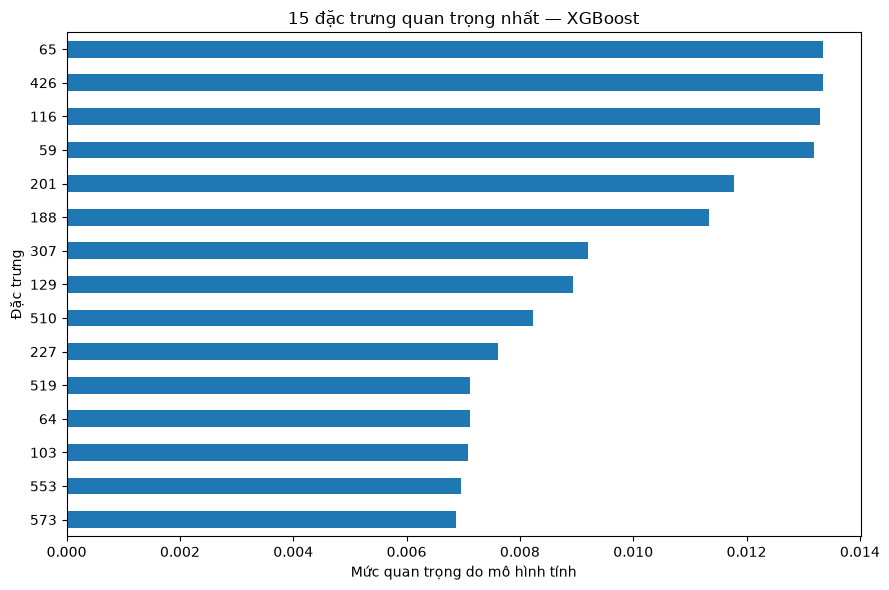

In [59]:
# Trực quan hóa đặc trưng quan trọng của XGBoost
import matplotlib.pyplot as plt

xgb_final_pipeline = final_training_runs[
    "XGBoost"
]["pipeline"]

# Truy tên đặc trưng qua các bước tiền xử lý.
feature_names = np.asarray(
    [str(column) for column in X_train.columns]
)

feature_names = feature_names[
    xgb_final_pipeline.named_steps[
        "missing"
    ].get_support()
]

feature_names = (
    xgb_final_pipeline.named_steps["impute"]
    .get_feature_names_out(feature_names)
)

feature_names = feature_names[
    xgb_final_pipeline.named_steps[
        "variance"
    ].get_support()
]

# Phương án được chọn bỏ SelectKBest.
assert locked_protocols["XGBoost"]["remove_selection"]

importances = (
    xgb_final_pipeline.named_steps[
        config.STEP_MODEL
    ].feature_importances_
)

assert len(feature_names) == len(importances)

xgb_feature_importance = (
    pd.DataFrame({
        "Đặc trưng": feature_names,
        "Mức quan trọng": importances,
    })
    .sort_values("Mức quan trọng", ascending=False)
    .reset_index(drop=True)
)

top_features = xgb_feature_importance.head(15)

display(top_features.round(4))

top_features.sort_values(
    "Mức quan trọng"
).plot.barh(
    x="Đặc trưng",
    y="Mức quan trọng",
    figsize=(9, 6),
    legend=False,
)

plt.title("15 đặc trưng quan trọng nhất — XGBoost")
plt.xlabel("Mức quan trọng do mô hình tính")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

## 18. Đánh giá cuối trên tập test

Đánh giá hai pipeline đã huấn luyện trên toàn bộ train:
- Random Forest bỏ chọn đặc trưng.
- XGBoost bỏ chọn đặc trưng, là ứng viên chính đã chọn.

Sử dụng nguyên ngưỡng được xác định từ OOF ở bước 17B.
Pipeline tự áp dụng các phép tiền xử lý đã học từ train
cho dữ liệu test.

Báo cáo:
- Recall, Precision, F1, Average Precision, ROC-AUC và Accuracy.
- Số Fail phát hiện đúng, Fail bỏ sót, Pass cảnh báo nhầm.
- Tổng số và tỷ lệ sản phẩm được cảnh báo.
- Confusion matrix của từng mô hình.

Không dùng kết quả test để điều chỉnh ngưỡng hoặc tuning lại.

In [60]:
# Kiểm tra dữ liệu và lấy mô hình , ngưỡng đã chốt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.utils.validation import check_is_fitted
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    accuracy_score,
)

import config

required_variables = [
    "X_train",
    "X_test",
    "y_test",
    "final_training_runs",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Thiếu biến: {missing_variables}. "
        "Cần dữ liệu đã chia và mô hình từ bước 17B."
    )

# Kiểm tra đặc trưng, nhãn và các mẫu giữa train/test.
assert X_test.index.equals(y_test.index)
assert X_train.columns.equals(X_test.columns)
assert X_train.index.intersection(X_test.index).empty
assert set(np.unique(y_test)) == {config.PASS, config.FAIL}

# Lấy đúng mô hình đã fit và ngưỡng đầy đủ độ chính xác.
test_locked_models = {}

for model_name in ["RF", "XGBoost"]:
    run = final_training_runs[model_name]
    pipeline = run["pipeline"]

    check_is_fitted(
        pipeline.named_steps[config.STEP_MODEL]
    )

    test_locked_models[model_name] = {
        "pipeline": pipeline,
        "threshold": float(run["threshold"]),
    }

print("Số mẫu test:", len(y_test))
print("Số Pass:", int((y_test == config.PASS).sum()))
print("Số Fail:", int((y_test == config.FAIL).sum()))

for name, item in test_locked_models.items():
    print(f"{name} — ngưỡng: {item['threshold']:.8f}")

Số mẫu test: 314
Số Pass: 297
Số Fail: 17
RF — ngưỡng: 0.12570028
XGBoost — ngưỡng: 0.09573009


In [61]:
# Dự đoán và tính chỉ số
test_runs = {}
test_rows = []

# Nhãn nhị phân cho các chỉ số đánh giá điểm dự đoán.
y_test_binary = (
    np.asarray(y_test) == config.FAIL
).astype(int)

for model_name, item in test_locked_models.items():
    pipeline = item["pipeline"]
    threshold = item["threshold"]

    # Lấy cột điểm dự đoán dành cho lớp Fail.
    fail_column = int(
        np.flatnonzero(
            np.asarray(pipeline.classes_) == config.FAIL
        )[0]
    )

    proba = pipeline.predict_proba(
        X_test
    )[:, fail_column]

    assert len(proba) == len(y_test)
    assert np.isfinite(proba).all()
    assert ((proba >= 0) & (proba <= 1)).all()

    # Áp dụng ngưỡng đã chọn từ train.
    predictions = np.where(
        proba >= threshold,
        config.FAIL,
        config.PASS,
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[config.PASS, config.FAIL],
    )

    tn, fp, fn, tp = cm.ravel()

    test_runs[model_name] = {
        "threshold": threshold,
        "proba": proba,
        "predictions": predictions,
        "confusion_matrix": cm,
    }

    test_rows.append({
        "Mô hình": model_name,
        "Ngưỡng": threshold,
        "Recall": recall_score(
            y_test, predictions,
            pos_label=config.FAIL, zero_division=0,
        ),
        "Precision": precision_score(
            y_test, predictions,
            pos_label=config.FAIL, zero_division=0,
        ),
        "F1": f1_score(
            y_test, predictions,
            pos_label=config.FAIL, zero_division=0,
        ),
        "AP": average_precision_score(
            y_test_binary, proba
        ),
        "ROC-AUC": roc_auc_score(
            y_test_binary, proba
        ),
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Fail bắt được": int(tp),
        "Fail bỏ sót": int(fn),
        "Pass cảnh báo nhầm": int(fp),
        "Pass cho qua đúng": int(tn),
        "Số cảnh báo": int(tp + fp),
        "Tỷ lệ cảnh báo (%)": (
            100 * (tp + fp) / len(y_test)
        ),
    })

test_summary = pd.DataFrame(test_rows)

print("CHỈ SỐ TRÊN TẬP TEST")
display(
    test_summary[[
        "Mô hình",
        "Ngưỡng",
        "Recall",
        "Precision",
        "F1",
        "AP",
        "ROC-AUC",
        "Accuracy",
    ]].round(4)
)

print("SỐ LƯỢNG DỰ ĐOÁN TRÊN TẬP TEST")
display(
    test_summary[[
        "Mô hình",
        "Fail bắt được",
        "Fail bỏ sót",
        "Pass cảnh báo nhầm",
        "Pass cho qua đúng",
        "Số cảnh báo",
        "Tỷ lệ cảnh báo (%)",
    ]].round(2)
)

CHỈ SỐ TRÊN TẬP TEST


,Mô hình,Ngưỡng,Recall,Precision,F1,AP,ROC-AUC,Accuracy
0,RF,0.1257,0.2941,0.0847,0.1316,0.0924,0.5805,0.7898
1,XGBoost,0.0957,0.2941,0.0735,0.1176,0.0851,0.5694,0.7611


SỐ LƯỢNG DỰ ĐOÁN TRÊN TẬP TEST


,Mô hình,Fail bắt được,Fail bỏ sót,Pass cảnh báo nhầm,Pass cho qua đúng,Số cảnh báo,Tỷ lệ cảnh báo (%)
0,RF,5,12,54,243,59,18.79
1,XGBoost,5,12,63,234,68,21.66


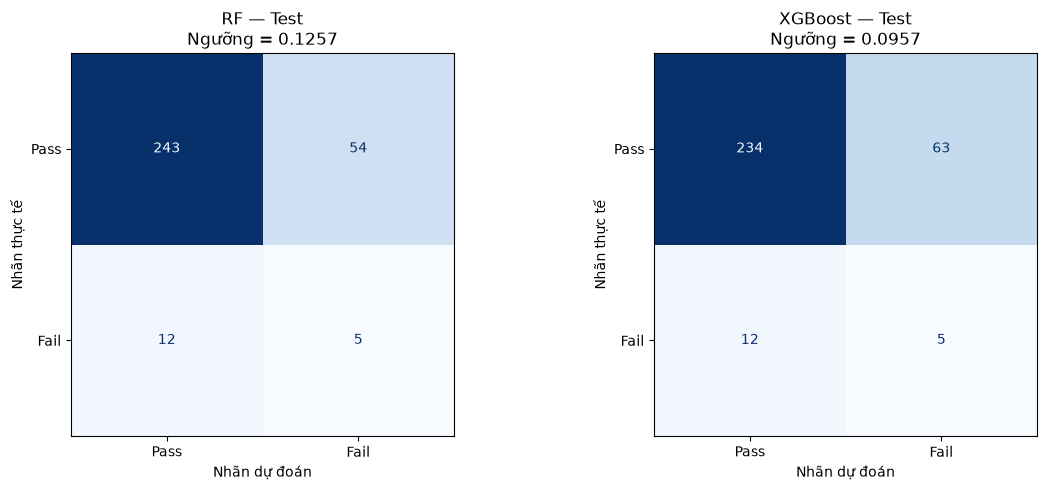

In [62]:
# Vẽ confusion matrix
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
)

for ax, model_name in zip(
    axes, ["RF", "XGBoost"]
):
    run = test_runs[model_name]

    ConfusionMatrixDisplay(
        confusion_matrix=run["confusion_matrix"],
        display_labels=["Pass", "Fail"],
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )

    ax.set_title(
        f"{model_name} — Test\n"
        f"Ngưỡng = {run['threshold']:.4f}"
    )
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")

plt.tight_layout()
plt.show()